<a href="https://colab.research.google.com/github/anuj04iitr/Skip-Free-Convolutional-Denoising-Autoencoders-for-Simulated-CT-Data/blob/main/Ai_Ml_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install nibabel

import os, glob, json, random
import numpy as np
import nibabel as nib
import torch
from google.colab import drive

drive.mount('/content/drive')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

PROJECT = '/content/drive/MyDrive/ct_dae_project'
RAW = '/content/msd_raw'
for sub in ['slices', 'phantoms', 'tiles', 'models', 'results', 'figures']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)
os.makedirs(RAW, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
if device == 'cuda':
    print('gpu:', torch.cuda.get_device_name(0))

URL = 'https://msd-for-monai.s3-us-west-2.amazonaws.com/Task09_Spleen.tar'
TAR = f'{RAW}/Task09_Spleen.tar'

if not os.path.exists(TAR):
    !wget -q --show-progress -O {TAR}.part {URL}
    os.rename(f'{TAR}.part', TAR)
print('archive size (GB):', round(os.path.getsize(TAR) / 1e9, 2))

if not os.path.isdir(f'{RAW}/Task09_Spleen'):
    !tar -xf {TAR} -C {RAW}

vol_paths = sorted(
    p for p in glob.glob(f'{RAW}/Task09_Spleen/imagesTr/*.nii.gz')
    if not os.path.basename(p).startswith('._')
)
print('volumes found:', len(vol_paths))

manifest = []
for p in vol_paths:
    header = nib.load(p).header
    manifest.append({
        'file': os.path.basename(p),
        'shape': [int(s) for s in header.get_data_shape()],
        'voxel_mm': [round(float(z), 3) for z in header.get_zooms()],
    })

for m in manifest[:5]:
    print(m)
print('slices per volume: min', min(m['shape'][2] for m in manifest),
      'max', max(m['shape'][2] for m in manifest))

first = nib.load(vol_paths[0]).get_fdata()
print('first volume HU range:', first.min(), first.max())

with open(f'{PROJECT}/volume_manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)

Mounted at /content/drive
device: cuda
gpu: Tesla T4
/content/msd_raw/Ta 100%[===================>]   1.50G  8.72MB/s    in 2m 38s  
archive size (GB): 1.61
volumes found: 41
{'file': 'spleen_10.nii.gz', 'shape': [512, 512, 55], 'voxel_mm': [0.977, 0.977, 5.0]}
{'file': 'spleen_12.nii.gz', 'shape': [512, 512, 168], 'voxel_mm': [0.754, 0.754, 1.5]}
{'file': 'spleen_13.nii.gz', 'shape': [512, 512, 77], 'voxel_mm': [0.742, 0.742, 2.5]}
{'file': 'spleen_14.nii.gz', 'shape': [512, 512, 54], 'voxel_mm': [0.852, 0.852, 5.0]}
{'file': 'spleen_16.nii.gz', 'shape': [512, 512, 61], 'voxel_mm': [0.793, 0.793, 8.0]}
slices per volume: min 31 max 168
first volume HU range: -1024.0 3072.0


1/41 spleen_10.nii.gz -> train, 20 slices
2/41 spleen_12.nii.gz -> train, 20 slices
3/41 spleen_13.nii.gz -> train, 20 slices
4/41 spleen_14.nii.gz -> val, 20 slices
5/41 spleen_16.nii.gz -> train, 20 slices
6/41 spleen_17.nii.gz -> train, 20 slices
7/41 spleen_18.nii.gz -> train, 20 slices
8/41 spleen_19.nii.gz -> test, 20 slices
9/41 spleen_2.nii.gz -> train, 20 slices
10/41 spleen_20.nii.gz -> train, 20 slices
11/41 spleen_21.nii.gz -> val, 20 slices
12/41 spleen_22.nii.gz -> train, 20 slices
13/41 spleen_24.nii.gz -> train, 20 slices
14/41 spleen_25.nii.gz -> train, 20 slices
15/41 spleen_26.nii.gz -> test, 20 slices
16/41 spleen_27.nii.gz -> train, 20 slices
17/41 spleen_28.nii.gz -> train, 20 slices
18/41 spleen_29.nii.gz -> train, 20 slices
19/41 spleen_3.nii.gz -> test, 20 slices
20/41 spleen_31.nii.gz -> train, 20 slices
21/41 spleen_32.nii.gz -> test, 20 slices
22/41 spleen_33.nii.gz -> train, 20 slices
23/41 spleen_38.nii.gz -> val, 20 slices
24/41 spleen_40.nii.gz -> val, 2

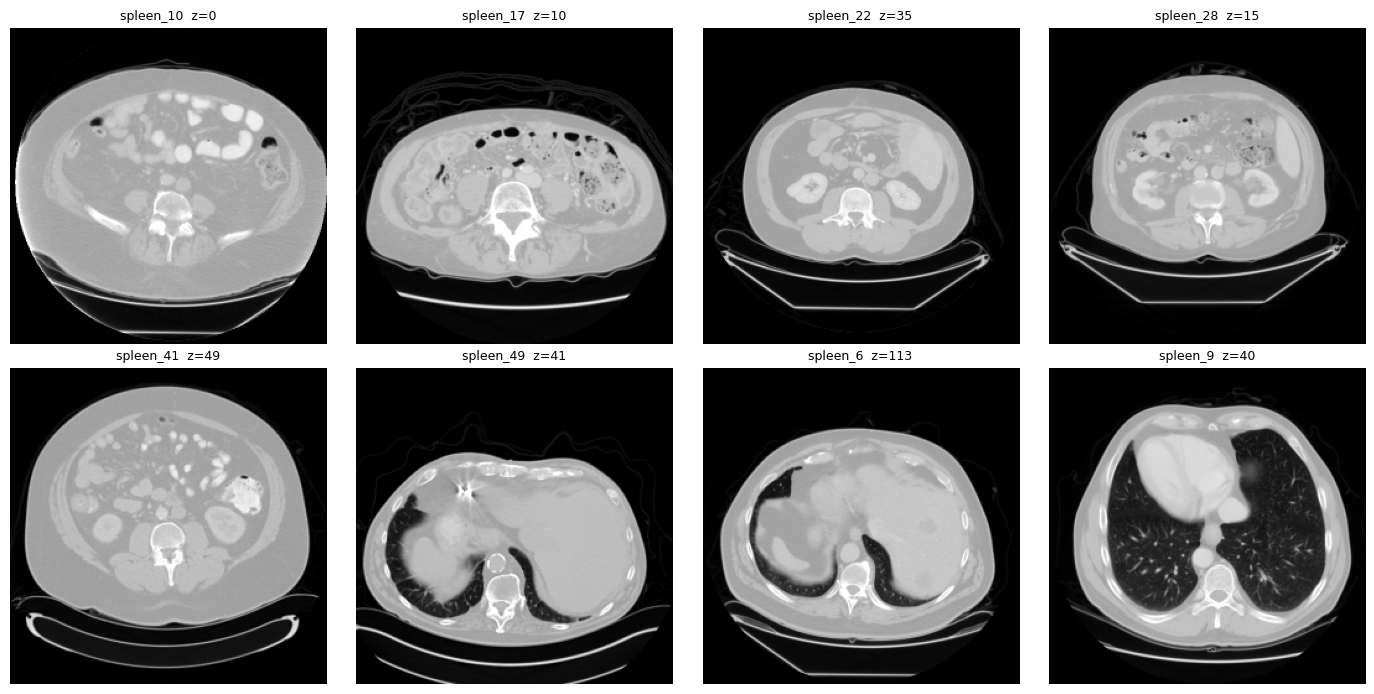

In [ ]:
import cv2
import shutil
import matplotlib.pyplot as plt

HU_LOW, HU_HIGH = -1000.0, 400.0
SLICES_PER_VOLUME = 20
BODY_HU = -300.0
BODY_MIN_FRACTION = 0.25
OUT_SIZE = 256
N_TRAIN, N_VAL = 29, 6

with open(f'{PROJECT}/volume_manifest.json') as f:
    manifest = json.load(f)
names = [m['file'] for m in manifest]

order = np.random.RandomState(SEED).permutation(len(names))
split_of = {}
for rank, idx in enumerate(order):
    if rank < N_TRAIN:
        split_of[names[idx]] = 'train'
    elif rank < N_TRAIN + N_VAL:
        split_of[names[idx]] = 'val'
    else:
        split_of[names[idx]] = 'test'

store = {s: {'x': [], 'meta': []} for s in ['train', 'val', 'test']}
png_dir = '/content/slices_png16'
for s in store:
    os.makedirs(f'{png_dir}/{s}', exist_ok=True)

for n, name in enumerate(names, 1):
    vol = nib.load(f'{RAW}/Task09_Spleen/imagesTr/{name}').get_fdata(dtype=np.float32)
    vol = np.clip(vol, HU_LOW, HU_HIGH)
    body_fraction = (vol > BODY_HU).mean(axis=(0, 1))
    vmin, vmax = float(vol.min()), float(vol.max())
    vol = (vol - vmin) / (vmax - vmin)

    candidates = np.where(body_fraction >= BODY_MIN_FRACTION)[0]
    if len(candidates) < SLICES_PER_VOLUME:
        candidates = np.arange(vol.shape[2])
    pick = np.unique(np.round(np.linspace(0, len(candidates) - 1, SLICES_PER_VOLUME)).astype(int))
    chosen = candidates[pick]

    split = split_of[name]
    for k in chosen:
        sl = np.ascontiguousarray(np.rot90(vol[:, :, k]), dtype=np.float32)
        sl = cv2.resize(sl, (OUT_SIZE, OUT_SIZE), interpolation=cv2.INTER_AREA)
        store[split]['x'].append(sl)
        store[split]['meta'].append({
            'volume': name,
            'slice_index': int(k),
            'hu_min': vmin,
            'hu_max': vmax,
        })
        png = np.round(np.clip(sl, 0, 1) * 65535).astype(np.uint16)
        cv2.imwrite(f'{png_dir}/{split}/{name[:-7]}_z{int(k):03d}.png', png)

    del vol
    print(f'{n}/{len(names)} {name} -> {split}, {len(chosen)} slices')

total = 0
for s in store:
    arr = np.stack(store[s]['x']).astype(np.float32)
    np.save(f'{PROJECT}/slices/{s}_slices.npy', arr)
    with open(f'{PROJECT}/slices/{s}_meta.json', 'w') as f:
        json.dump(store[s]['meta'], f)
    n_vol = len({m['volume'] for m in store[s]['meta']})
    total += len(arr)
    print(s, arr.shape, 'volumes:', n_vol, 'min/max:', round(float(arr.min()), 3), round(float(arr.max()), 3))

with open(f'{PROJECT}/split.json', 'w') as f:
    json.dump(split_of, f, indent=2)

shutil.make_archive(f'{PROJECT}/slices/slices_png16', 'zip', png_dir)
print('total real slices:', total)

train = np.load(f'{PROJECT}/slices/train_slices.npy')
train_meta = store['train']['meta']
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.ravel(), np.linspace(0, len(train) - 1, 8).astype(int)):
    ax.imshow(train[i], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"{train_meta[i]['volume'][:-7]}  z={train_meta[i]['slice_index']}", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/sample_clean_slices.png', dpi=150)
plt.show()

train (210, 256, 256) class counts: [42, 42, 42, 42, 42] min/max: 0.0 1.0
val (45, 256, 256) class counts: [9, 9, 9, 9, 9] min/max: 0.0 1.0
test (45, 256, 256) class counts: [9, 9, 9, 9, 9] min/max: 0.0 1.0
phantom slices: 300
real slices: 820
combined total: 1120


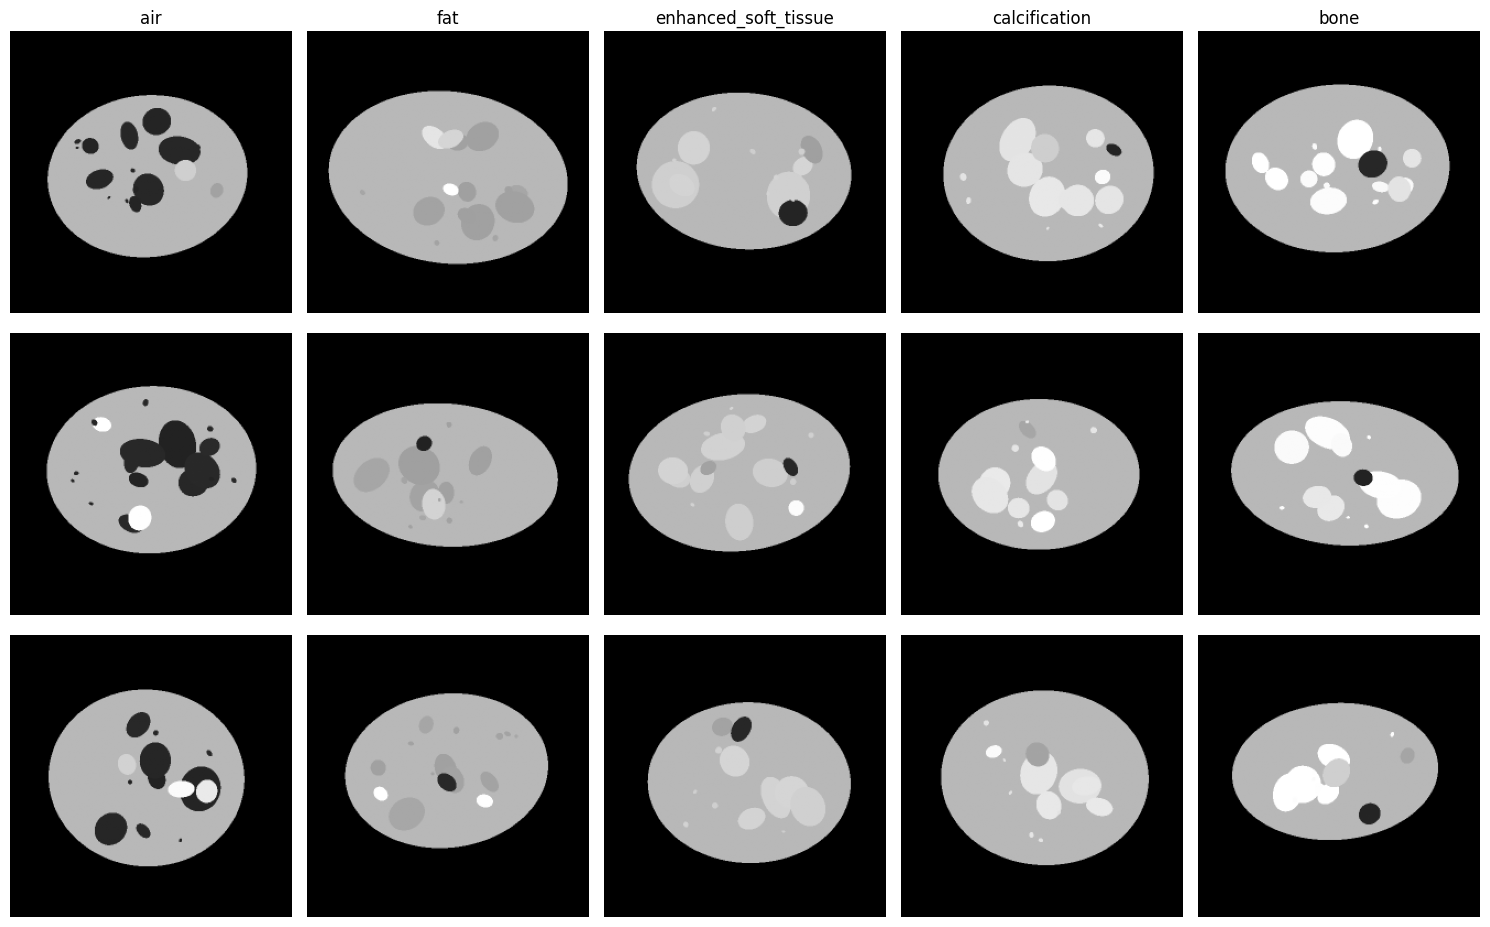

In [ ]:
import os, json, shutil
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

SEED = 42
PROJECT = '/content/drive/MyDrive/ct_dae_project'

PH_SIZE = 256
SS = 2
S = PH_SIZE * SS
CLASS_NAMES = ['air', 'fat', 'enhanced_soft_tissue', 'calcification', 'bone']
CLASS_VALUES = [0.15, 0.64, 0.82, 0.90, 0.99]
BODY_VALUE = 0.72
PER_CLASS = {'train': 42, 'val': 9, 'test': 9}
PER_CLASS_TOTAL = sum(PER_CLASS.values())

YY, XX = np.mgrid[0:S, 0:S].astype(np.float32)

def ellipse(cy, cx, ay, ax, theta):
    dx, dy = XX - cx, YY - cy
    c, s = np.cos(theta), np.sin(theta)
    u = (dx * c + dy * s) / ax
    v = (-dx * s + dy * c) / ay
    return (u * u + v * v) <= 1.0

def make_phantom(cls, seed):
    rng = np.random.RandomState(seed)
    img = np.zeros((S, S), dtype=np.float32)

    cy = (PH_SIZE / 2 + rng.uniform(-6, 6)) * SS
    cx = (PH_SIZE / 2 + rng.uniform(-6, 6)) * SS
    ay = rng.uniform(62, 82) * SS
    ax = rng.uniform(88, 112) * SS
    theta = rng.uniform(-0.15, 0.15)
    body = ellipse(cy, cx, ay, ax, theta)
    img[body] = BODY_VALUE
    ct, st = np.cos(theta), np.sin(theta)

    def draw(radius_range, value, count, inner):
        for _ in range(count):
            r = rng.uniform(*radius_range) * SS
            ratio = rng.uniform(0.6, 1.0)
            ang = rng.uniform(0, 2 * np.pi)
            rad = inner * np.sqrt(rng.uniform(0, 1))
            u, v = rad * np.cos(ang), rad * np.sin(ang)
            py = cy + u * ax * st + v * ay * ct
            px = cx + u * ax * ct - v * ay * st
            m = ellipse(py, px, r * ratio, r, rng.uniform(0, np.pi)) & body
            img[m] = np.clip(value + rng.uniform(-0.015, 0.015), 0, 1)

    dominant = CLASS_VALUES[cls]
    draw((7, 22), dominant, rng.randint(5, 9), 0.7)
    others = [i for i in range(len(CLASS_VALUES)) if i != cls]
    for o in rng.choice(others, size=rng.randint(2, 4), replace=True):
        draw((6, 14), CLASS_VALUES[o], 1, 0.75)
    draw((1.5, 3.5), dominant, rng.randint(4, 9), 0.85)

    out = cv2.resize(img, (PH_SIZE, PH_SIZE), interpolation=cv2.INTER_AREA)
    return np.clip(out, 0, 1).astype(np.float32)

data = {s: {'x': [], 'y': [], 'seed': []} for s in PER_CLASS}
for cls in range(len(CLASS_NAMES)):
    seeds = [10000 + cls * 1000 + k for k in range(PER_CLASS_TOTAL)]
    start = 0
    for split, n in PER_CLASS.items():
        for sd in seeds[start:start + n]:
            data[split]['x'].append(make_phantom(cls, sd))
            data[split]['y'].append(cls)
            data[split]['seed'].append(sd)
        start += n

os.makedirs(f'{PROJECT}/phantoms', exist_ok=True)
png_dir = '/content/phantoms_png16'
shuffle_rng = np.random.RandomState(SEED)
meta = {'class_names': CLASS_NAMES, 'class_values': CLASS_VALUES,
        'body_value': BODY_VALUE, 'seeds': {}}
total_phantoms = 0

for split in data:
    x = np.stack(data[split]['x']).astype(np.float32)
    y = np.array(data[split]['y'], dtype=np.int64)
    sd = np.array(data[split]['seed'], dtype=np.int64)
    p = shuffle_rng.permutation(len(x))
    x, y, sd = x[p], y[p], sd[p]

    np.save(f'{PROJECT}/phantoms/{split}_phantoms.npy', x)
    np.save(f'{PROJECT}/phantoms/{split}_labels.npy', y)
    meta['seeds'][split] = [int(v) for v in sd]

    os.makedirs(f'{png_dir}/{split}', exist_ok=True)
    for i in range(len(x)):
        png = np.round(x[i] * 65535).astype(np.uint16)
        cv2.imwrite(f'{png_dir}/{split}/phantom_{split}_{i:03d}_c{int(y[i])}.png', png)

    total_phantoms += len(x)
    print(split, x.shape, 'class counts:', np.bincount(y, minlength=len(CLASS_NAMES)).tolist(),
          'min/max:', round(float(x.min()), 3), round(float(x.max()), 3))

with open(f'{PROJECT}/phantoms/phantom_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
shutil.make_archive(f'{PROJECT}/phantoms/phantoms_png16', 'zip', png_dir)

n_real = sum(len(np.load(f'{PROJECT}/slices/{s}_slices.npy', mmap_mode='r')) for s in ['train', 'val', 'test'])
print('phantom slices:', total_phantoms)
print('real slices:', n_real)
print('combined total:', n_real + total_phantoms)

train_x = np.load(f'{PROJECT}/phantoms/train_phantoms.npy')
train_y = np.load(f'{PROJECT}/phantoms/train_labels.npy')
fig, axes = plt.subplots(3, 5, figsize=(15, 9.5))
for c in range(len(CLASS_NAMES)):
    idx = np.where(train_y == c)[0][:3]
    for r, i in enumerate(idx):
        axes[r, c].imshow(train_x[i], cmap='gray', vmin=0, vmax=1)
        axes[r, c].axis('off')
        if r == 0:
            axes[r, c].set_title(CLASS_NAMES[c])
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/sample_phantoms.png', dpi=150)
plt.show()

In [ ]:
%%writefile /content/drive/MyDrive/ct_dae_project/ct_noise.py
import math
import numpy as np
import torch

MU_MAX = 6.0
N0_MIN, N0_MAX = 5e4, 2e5
SIGMA_MIN, SIGMA_MAX = 0.01, 0.03


def add_noise_np(clean, n0, sigma, rng, mu_max=MU_MAX):
    mu = np.asarray(clean, dtype=np.float64) * mu_max
    photons = n0 * np.exp(-mu)
    counts = np.maximum(rng.poisson(photons).astype(np.float64), 1.0)
    noisy = -np.log(counts / n0) / mu_max
    noisy = noisy + rng.normal(0.0, 1.0, size=noisy.shape) * sigma
    return noisy.astype(np.float32)


def sample_params_np(rng, size=None):
    n0 = np.exp(rng.uniform(math.log(N0_MIN), math.log(N0_MAX), size))
    sigma = rng.uniform(SIGMA_MIN, SIGMA_MAX, size)
    return n0, sigma


def add_noise_torch(clean, n0, sigma, mu_max=MU_MAX):
    photons = n0 * torch.exp(-clean * mu_max)
    counts = torch.poisson(photons).clamp_min(1.0)
    noisy = -torch.log(counts / n0) / mu_max
    return noisy + torch.randn_like(noisy) * sigma


def sample_params_torch(batch, device):
    u = torch.rand(batch, 1, 1, 1, device=device)
    n0 = torch.exp(math.log(N0_MIN) + u * (math.log(N0_MAX) - math.log(N0_MIN)))
    sigma = SIGMA_MIN + torch.rand(batch, 1, 1, 1, device=device) * (SIGMA_MAX - SIGMA_MIN)
    return n0, sigma

Writing /content/drive/MyDrive/ct_dae_project/ct_noise.py


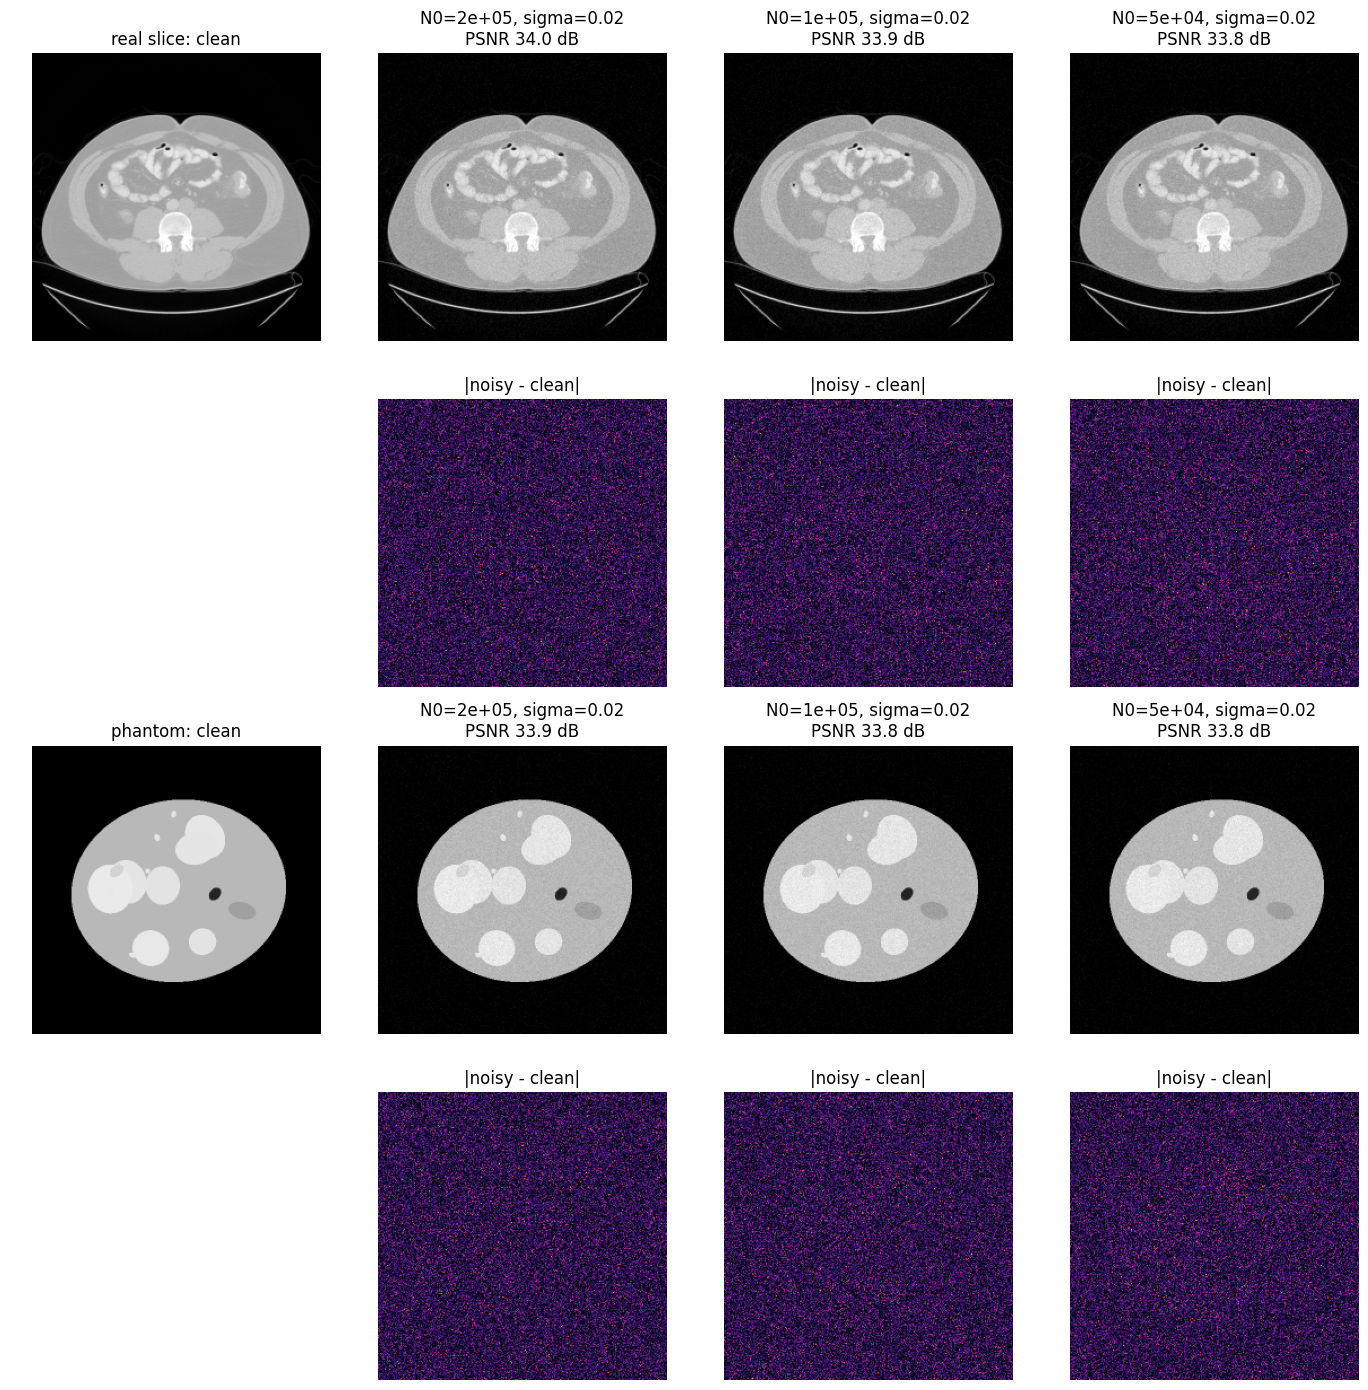

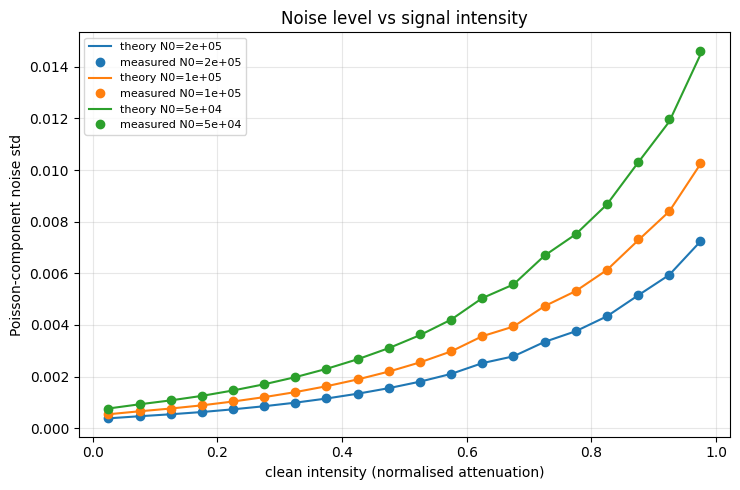

noise std ratio, brightest vs darkest populated bin (N0=5e4): 19.2
expected photons at brightest pixel, lowest dose: 123.9
fraction of zero-count pixels, lowest dose: 0.0
    N0  sigma  PSNR_dB  SSIM
 50000   0.01   39.132 0.929
 50000   0.02   33.745 0.796
 50000   0.03   30.354 0.663
100000   0.01   39.541 0.933
100000   0.02   33.847 0.799
100000   0.03   30.412 0.665
200000   0.01   39.757 0.935
200000   0.02   33.916 0.800
200000   0.03   30.426 0.666


In [ ]:
import os, sys, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise
importlib.reload(ct_noise)
from ct_noise import add_noise_np, MU_MAX

test_real = np.load(f'{PROJECT}/slices/test_slices.npy')
test_ph = np.load(f'{PROJECT}/phantoms/test_phantoms.npy')
rng = np.random.RandomState(0)
levels = [2e5, 1e5, 5e4]

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for r, (img, tag) in enumerate([(test_real[70], 'real slice'), (test_ph[7], 'phantom')]):
    axes[2 * r, 0].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[2 * r, 0].set_title(f'{tag}: clean')
    for c, n0 in enumerate(levels, start=1):
        noisy = add_noise_np(img, n0, 0.02, rng)
        axes[2 * r, c].imshow(np.clip(noisy, 0, 1), cmap='gray', vmin=0, vmax=1)
        axes[2 * r, c].set_title(f'N0={n0:.0e}, sigma=0.02\nPSNR {psnr(img, noisy, data_range=1.0):.1f} dB')
        axes[2 * r + 1, c].imshow(np.abs(noisy - img), cmap='magma', vmin=0, vmax=0.1)
        axes[2 * r + 1, c].set_title('|noisy - clean|')
    for ax in axes[2 * r:2 * r + 2].ravel():
        ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/noise_model_examples.png', dpi=150)
plt.show()

bins = np.linspace(0, 1, 21)
centres = 0.5 * (bins[1:] + bins[:-1])
flat = test_real.reshape(-1).astype(np.float64)
which = np.clip(np.digitize(flat, bins) - 1, 0, 19)
counts_per_bin = np.bincount(which, minlength=20)
valid = counts_per_bin > 2000

plt.figure(figsize=(7.5, 5))
measured_at = {}
for n0 in levels:
    noisy = add_noise_np(test_real, n0, 0.0, rng).reshape(-1).astype(np.float64)
    err2 = (noisy - flat) ** 2
    measured = np.sqrt(np.bincount(which, weights=err2, minlength=20) / np.maximum(counts_per_bin, 1))
    theory_var = np.bincount(which, weights=np.exp(MU_MAX * flat) / (n0 * MU_MAX ** 2), minlength=20)
    theory = np.sqrt(theory_var / np.maximum(counts_per_bin, 1))
    line, = plt.plot(centres[valid], theory[valid], label=f'theory N0={n0:.0e}')
    plt.plot(centres[valid], measured[valid], 'o', color=line.get_color(), label=f'measured N0={n0:.0e}')
    measured_at[n0] = measured[valid]
plt.xlabel('clean intensity (normalised attenuation)')
plt.ylabel('Poisson-component noise std')
plt.title('Noise level vs signal intensity')
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/noise_std_vs_intensity.png', dpi=150)
plt.show()

m = measured_at[5e4]
print('noise std ratio, brightest vs darkest populated bin (N0=5e4):', round(float(m[-1] / m[0]), 1))

lowest_photons = 5e4 * np.exp(-MU_MAX * float(test_real.max()))
zero_fraction = float((rng.poisson(5e4 * np.exp(-MU_MAX * test_real.astype(np.float64))) == 0).mean())
print('expected photons at brightest pixel, lowest dose:', round(lowest_photons, 1))
print('fraction of zero-count pixels, lowest dose:', zero_fraction)

rows = []
subset = test_real[::6]
for n0 in [5e4, 1e5, 2e5]:
    for sg in [0.01, 0.02, 0.03]:
        p, s = [], []
        for img in subset:
            noisy = add_noise_np(img, n0, sg, rng)
            p.append(psnr(img, noisy, data_range=1.0))
            s.append(ssim(img, noisy, data_range=1.0))
        rows.append({'N0': int(n0), 'sigma': sg, 'PSNR_dB': np.mean(p), 'SSIM': np.mean(s)})
table = pd.DataFrame(rows).round(3)
print(table.to_string(index=False))
table.to_csv(f'{PROJECT}/results/noisy_input_baseline.csv', index=False)

In [ ]:
%%writefile /content/drive/MyDrive/ct_dae_project/ct_data.py
import numpy as np
import torch

TILE = 128


def window_2d(size):
    w = np.hanning(size + 2)[1:-1].astype(np.float64)
    return np.outer(w, w)


def tile_positions(length, size, stride):
    pos = list(range(0, length - size + 1, stride))
    if pos[-1] != length - size:
        pos.append(length - size)
    return pos


def extract_tiles(img, size=TILE, stride=TILE):
    ys = tile_positions(img.shape[0], size, stride)
    xs = tile_positions(img.shape[1], size, stride)
    return np.stack([img[y:y + size, x:x + size] for y in ys for x in xs])


def reassemble(tiles, shape, size=TILE, stride=TILE):
    ys = tile_positions(shape[0], size, stride)
    xs = tile_positions(shape[1], size, stride)
    w = np.ones((size, size)) if stride >= size else window_2d(size)
    acc = np.zeros(shape, dtype=np.float64)
    norm = np.zeros(shape, dtype=np.float64)
    k = 0
    for y in ys:
        for x in xs:
            acc[y:y + size, x:x + size] += tiles[k] * w
            norm[y:y + size, x:x + size] += w
            k += 1
    return (acc / norm).astype(np.float32)


def augment(x):
    n = x.shape[0]
    op = torch.randint(0, 8, (n,), device=x.device)
    out = torch.empty_like(x)
    for k in range(8):
        idx = (op == k).nonzero(as_tuple=True)[0]
        if idx.numel() == 0:
            continue
        t = torch.rot90(x[idx], k % 4, dims=(2, 3))
        if k >= 4:
            t = torch.flip(t, dims=(3,))
        out[idx] = t
    return out

Writing /content/drive/MyDrive/ct_dae_project/ct_data.py


train tiles (3160, 128, 128) | real 2320 | phantom 840
val tiles (660, 128, 128) | real 480 | phantom 180
val noisy tiles (660, 128, 128)
mixed                  noisy PSNR 34.49 dB  (real 34.62, phantom 34.15)
N0_50000_sigma_0.02    noisy PSNR 33.76 dB  (real 33.74, phantom 33.79)
N0_75000_sigma_0.02    noisy PSNR 33.83 dB  (real 33.82, phantom 33.86)
N0_100000_sigma_0.02   noisy PSNR 33.87 dB  (real 33.86, phantom 33.89)
N0_150000_sigma_0.02   noisy PSNR 33.90 dB  (real 33.90, phantom 33.92)
N0_200000_sigma_0.02   noisy PSNR 33.92 dB  (real 33.92, phantom 33.94)
N0_100000_sigma_0.01   noisy PSNR 39.57 dB  (real 39.54, phantom 39.64)
N0_100000_sigma_0.03   noisy PSNR 30.41 dB  (real 30.41, phantom 30.41)
test slices: 165 (real 120 + phantom 45 )
stride 128: 4 tiles per slice, max reassembly error 0.0e+00
stride 64: 9 tiles per slice, max reassembly error 0.0e+00


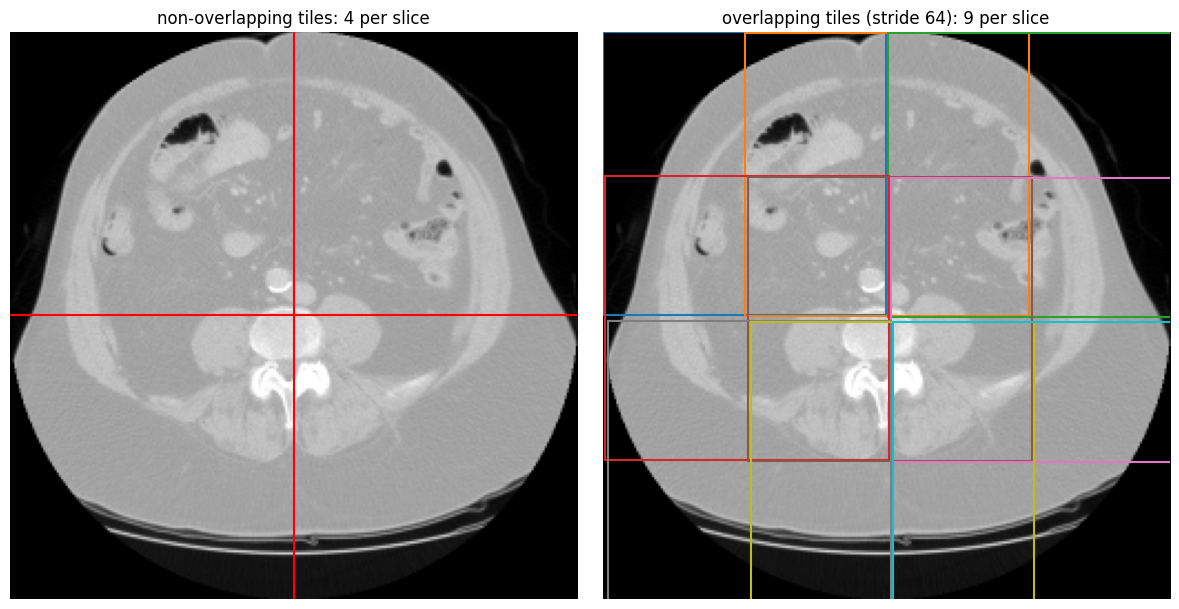

augment: shape kept True | pixel sums kept True | tiles changed 59 of 64


In [ ]:
import os, sys, json, importlib
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data
importlib.reload(ct_noise)
importlib.reload(ct_data)
from ct_noise import add_noise_np, sample_params_np
from ct_data import extract_tiles, reassemble

TILE = 128
for sub in ['tiles', 'testsets']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)


def load(split):
    real = np.load(f'{PROJECT}/slices/{split}_slices.npy')
    ph = np.load(f'{PROJECT}/phantoms/{split}_phantoms.npy')
    lab = np.load(f'{PROJECT}/phantoms/{split}_labels.npy')
    return real, ph, lab


def to_tiles(arr):
    return np.concatenate([extract_tiles(a, TILE, TILE) for a in arr]).astype(np.float32)


for split in ['train', 'val']:
    real, ph, lab = load(split)
    tiles = np.concatenate([to_tiles(real), to_tiles(ph)])
    source = np.concatenate([np.zeros(len(real) * 4, dtype=np.int64), np.ones(len(ph) * 4, dtype=np.int64)])
    tile_label = np.concatenate([np.full(len(real) * 4, -1, dtype=np.int64), np.repeat(lab, 4)])
    np.save(f'{PROJECT}/tiles/{split}_tiles.npy', tiles)
    np.save(f'{PROJECT}/tiles/{split}_tile_source.npy', source)
    np.save(f'{PROJECT}/tiles/{split}_tile_label.npy', tile_label)
    print(split, 'tiles', tiles.shape, '| real', int((source == 0).sum()), '| phantom', int((source == 1).sum()))
    if split == 'val':
        rng = np.random.RandomState(123)
        n0, sg = sample_params_np(rng, size=len(tiles))
        noisy = np.stack([add_noise_np(t, n0[i], sg[i], rng) for i, t in enumerate(tiles)])
        np.save(f'{PROJECT}/tiles/val_tiles_noisy.npy', noisy)
        np.save(f'{PROJECT}/tiles/val_tile_params.npy', np.stack([n0, sg], axis=1).astype(np.float32))
        print('val noisy tiles', noisy.shape)

test_real, test_ph, test_lab = load('test')
clean_all = np.concatenate([test_real, test_ph]).astype(np.float32)
labels_all = np.concatenate([np.full(len(test_real), -1, dtype=np.int64), test_lab])
np.save(f'{PROJECT}/testsets/clean.npy', clean_all)
np.save(f'{PROJECT}/testsets/labels.npy', labels_all)

conditions = {'mixed': None}
for n0 in [50000, 75000, 100000, 150000, 200000]:
    conditions[f'N0_{n0}_sigma_0.02'] = (n0, 0.02)
for sg in [0.01, 0.03]:
    conditions[f'N0_100000_sigma_{sg}'] = (100000, sg)

for i, (name, cfg) in enumerate(conditions.items()):
    rng = np.random.RandomState(1000 + i)
    if cfg is None:
        n0s, sgs = sample_params_np(rng, size=len(clean_all))
    else:
        n0s = np.full(len(clean_all), cfg[0], dtype=np.float64)
        sgs = np.full(len(clean_all), cfg[1], dtype=np.float64)
    noisy = np.stack([add_noise_np(c, n0s[j], sgs[j], rng) for j, c in enumerate(clean_all)])
    np.save(f'{PROJECT}/testsets/noisy_{name}.npy', noisy)
    mse = ((noisy - clean_all) ** 2).mean(axis=(1, 2))
    p = 10 * np.log10(1.0 / mse)
    print(f'{name:22s} noisy PSNR {p.mean():.2f} dB  (real {p[labels_all < 0].mean():.2f}, phantom {p[labels_all >= 0].mean():.2f})')

with open(f'{PROJECT}/testsets/conditions.json', 'w') as f:
    json.dump(list(conditions), f, indent=2)
print('test slices:', len(clean_all), '(real', int((labels_all < 0).sum()), '+ phantom', int((labels_all >= 0).sum()), ')')

probe = test_real[0]
for stride in [128, 64]:
    t = extract_tiles(probe, TILE, stride)
    back = reassemble(t, probe.shape, TILE, stride)
    print(f'stride {stride}: {len(t)} tiles per slice, max reassembly error {np.abs(back - probe).max():.1e}')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(probe, cmap='gray', vmin=0, vmax=1)
axes[0].axhline(TILE - 0.5, color='red')
axes[0].axvline(TILE - 0.5, color='red')
axes[0].set_title('non-overlapping tiles: 4 per slice')
axes[1].imshow(probe, cmap='gray', vmin=0, vmax=1)
colors = plt.cm.tab10(np.linspace(0, 1, 9))
k = 0
for y in [0, 64, 128]:
    for x in [0, 64, 128]:
        axes[1].add_patch(Rectangle((x - 0.5 + k * 0.4, y - 0.5 + k * 0.4), TILE, TILE, fill=False, edgecolor=colors[k], lw=1.5))
        k += 1
axes[1].set_title('overlapping tiles (stride 64): 9 per slice')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/tiling_scheme.png', dpi=150)
plt.show()

sample = torch.from_numpy(np.load(f'{PROJECT}/tiles/train_tiles.npy')[:64]).unsqueeze(1)
aug = ct_data.augment(sample)
same_sums = torch.allclose(aug.sum(dim=(1, 2, 3)), sample.sum(dim=(1, 2, 3)), rtol=1e-4)
changed = int((aug != sample).flatten(1).any(dim=1).sum())
print('augment: shape kept', aug.shape == sample.shape, '| pixel sums kept', same_sums, '| tiles changed', changed, 'of 64')

In [ ]:
%%writefile /content/drive/MyDrive/ct_dae_project/ct_metrics.py
import numpy as np
import cv2
from scipy import ndimage
from skimage.metrics import structural_similarity
from skimage.restoration import denoise_nl_means


def mse_each(clean, pred):
    return ((clean.astype(np.float64) - pred.astype(np.float64)) ** 2).mean(axis=(1, 2))


def psnr_each(clean, pred):
    return 10 * np.log10(1.0 / np.maximum(mse_each(clean, pred), 1e-12))


def ssim_each(clean, pred):
    return np.array([structural_similarity(c, p, data_range=1.0) for c, p in zip(clean, pred)])


def lapvar_each(imgs):
    return np.array([cv2.Laplacian(i.astype(np.float64), cv2.CV_64F).var() for i in imgs])


def evaluate(clean, pred, labels):
    pred = np.clip(pred, 0.0, 1.0)
    per = {
        'PSNR': psnr_each(clean, pred),
        'SSIM': ssim_each(clean, pred),
        'MSE': mse_each(clean, pred),
        'LapVar': lapvar_each(pred),
    }
    out = {}
    for group, mask in [('all', np.ones(len(clean), dtype=bool)), ('real', labels < 0), ('phantom', labels >= 0)]:
        for k, v in per.items():
            out[f'{k}_{group}'] = float(v[mask].mean())
    return out, per


def gaussian_filter_batch(x, sigma):
    return np.stack([ndimage.gaussian_filter(i, sigma=sigma, mode='reflect') for i in x]).astype(np.float32)


def median_filter_batch(x, size):
    return np.stack([ndimage.median_filter(i, size=size, mode='reflect') for i in x]).astype(np.float32)


def estimate_noise_sigma(img):
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float64)
    r = ndimage.convolve(img.astype(np.float64), k, mode='reflect')
    return float(np.median(np.abs(r)) / 0.6745 / 6.0)


def nlm_filter_batch(x, h_scale, patch_size=5, patch_distance=6):
    out = []
    for i in x:
        s = estimate_noise_sigma(i)
        out.append(denoise_nl_means(i, h=h_scale * s, sigma=s, patch_size=patch_size,
                                    patch_distance=patch_distance, fast_mode=True))
    return np.stack(out).astype(np.float32)

Writing /content/drive/MyDrive/ct_dae_project/ct_metrics.py


In [ ]:
import os, sys, json, time, importlib
import numpy as np
import pandas as pd
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_metrics
importlib.reload(ct_metrics)
from ct_metrics import (psnr_each, lapvar_each, evaluate, gaussian_filter_batch,
                        median_filter_batch, nlm_filter_batch)

os.makedirs(f'{PROJECT}/results/preds', exist_ok=True)

val_clean = np.load(f'{PROJECT}/tiles/val_tiles.npy')
val_noisy = np.load(f'{PROJECT}/tiles/val_tiles_noisy.npy')
pick = np.random.RandomState(7).choice(len(val_clean), 80, replace=False)
vc, vn = val_clean[pick], val_noisy[pick]


def val_psnr(pred):
    return float(psnr_each(vc, np.clip(pred, 0.0, 1.0)).mean())


search = {
    'gaussian': {s: val_psnr(gaussian_filter_batch(vn, s)) for s in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]},
    'median': {k: val_psnr(median_filter_batch(vn, k)) for k in [3, 5, 7]},
    'nlm': {h: val_psnr(nlm_filter_batch(vn, h)) for h in [0.6, 0.8, 1.0, 1.2, 1.5]},
}
best = {name: max(grid, key=grid.get) for name, grid in search.items()}
print('validation PSNR of the noisy tiles:', round(val_psnr(vn), 2), 'dB')
for name, grid in search.items():
    print(name, {k: round(v, 2) for k, v in grid.items()}, '-> best', best[name])
with open(f'{PROJECT}/results/classical_params.json', 'w') as f:
    json.dump({k: float(v) for k, v in best.items()}, f, indent=2)

methods = {
    'noisy_input': lambda x: x,
    'gaussian': lambda x: gaussian_filter_batch(x, best['gaussian']),
    'median': lambda x: median_filter_batch(x, int(best['median'])),
    'nlm': lambda x: nlm_filter_batch(x, best['nlm']),
}

clean = np.load(f'{PROJECT}/testsets/clean.npy')
labels = np.load(f'{PROJECT}/testsets/labels.npy')
with open(f'{PROJECT}/testsets/conditions.json') as f:
    conditions = json.load(f)

rows = []
for cond in conditions:
    noisy = np.load(f'{PROJECT}/testsets/noisy_{cond}.npy')
    for name, fn in methods.items():
        t0 = time.time()
        pred = np.clip(fn(noisy), 0.0, 1.0)
        secs = time.time() - t0
        m, _ = evaluate(clean, pred, labels)
        rows.append({'condition': cond, 'method': name, 'seconds': round(secs, 2), **m})
        if cond == 'mixed' and name != 'noisy_input':
            np.save(f'{PROJECT}/results/preds/{name}_mixed.npy', pred.astype(np.float32))
    print(cond, 'done')

df = pd.DataFrame(rows)
df.to_csv(f'{PROJECT}/results/classical_metrics.csv', index=False)

print('\nclean slices Laplacian variance (sharpness reference):', round(float(lapvar_each(clean).mean()), 5))
cols = ['PSNR_all', 'SSIM_all', 'MSE_all', 'LapVar_all', 'PSNR_real', 'PSNR_phantom']
print('\nmixed-dose test set')
print(df[df.condition == 'mixed'].set_index('method')[cols].round(4).to_string())
print('\nPSNR (dB) by condition')
print(df.pivot(index='method', columns='condition', values='PSNR_all').reindex(columns=conditions).round(2).to_string())

validation PSNR of the noisy tiles: 36.05 dB
gaussian {0.5: 36.79, 0.75: 33.45, 1.0: 31.14, 1.25: 29.5, 1.5: 28.26, 2.0: 26.49} -> best 0.5
median {3: 37.16, 5: 34.23, 7: 32.02} -> best 3
nlm {0.6: 43.13, 0.8: 43.4, 1.0: 43.32, 1.2: 43.01, 1.5: 42.34} -> best 0.8
mixed done
N0_50000_sigma_0.02 done
N0_75000_sigma_0.02 done
N0_100000_sigma_0.02 done
N0_150000_sigma_0.02 done
N0_200000_sigma_0.02 done
N0_100000_sigma_0.01 done
N0_100000_sigma_0.03 done

clean slices Laplacian variance (sharpness reference): 0.01136

mixed-dose test set
             PSNR_all  SSIM_all  MSE_all  LapVar_all  PSNR_real  PSNR_phantom
method                                                                       
noisy_input   35.5591    0.7565   0.0003      0.0174    35.4564       35.8328
gaussian      36.1931    0.8615   0.0003      0.0068    35.9556       36.8265
median        35.0319    0.9053   0.0004      0.0074    32.4825       41.8300
nlm           42.3245    0.9693   0.0001      0.0112    40.3529       

In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/ct_dae_project'
print(os.path.isdir(PROJECT))
print(sorted(os.listdir(PROJECT)))

Mounted at /content/drive
True
['__pycache__', 'ct_data.py', 'ct_metrics.py', 'ct_noise.py', 'figures', 'models', 'phantoms', 'results', 'slices', 'split.json', 'testsets', 'tiles', 'volume_manifest.json']


In [ ]:
%%writefile /content/drive/MyDrive/ct_dae_project/ct_models.py
import torch
import torch.nn as nn


def down_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


def up_block(cin, cout):
    return nn.Sequential(
        nn.ConvTranspose2d(cin, cout, 4, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


class ConvAE(nn.Module):
    def __init__(self, width=128, variational=False):
        super().__init__()
        self.width = width
        self.variational = variational
        self.encoder = nn.Sequential(down_block(1, 32), down_block(32, 64),
                                     down_block(64, 128), down_block(128, 256))
        self.to_latent = nn.Conv2d(256, width, 3, padding=1)
        self.to_logvar = nn.Conv2d(256, width, 3, padding=1) if variational else None
        self.from_latent = nn.Sequential(
            nn.Conv2d(width, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )
        self.decoder = nn.Sequential(up_block(256, 128), up_block(128, 64),
                                     up_block(64, 32), up_block(32, 32))
        self.head = nn.Conv2d(32, 1, 3, padding=1)

    def encode(self, x):
        h = self.encoder(x)
        mu = self.to_latent(h)
        if self.variational:
            return mu, self.to_logvar(h).clamp(-10.0, 10.0)
        return mu, None

    def decode(self, z):
        return torch.sigmoid(self.head(self.decoder(self.from_latent(z))))

    def forward(self, x):
        mu, logvar = self.encode(x)
        if self.variational and self.training:
            z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
            return self.decode(z), (mu, logvar)
        extra = (mu, logvar) if self.variational else None
        return self.decode(mu), extra


class DnCNN(nn.Module):
    def __init__(self, depth=17, channels=64):
        super().__init__()
        layers = [nn.Conv2d(1, channels, 3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [
                nn.Conv2d(channels, channels, 3, padding=1, bias=False),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True),
            ]
        layers.append(nn.Conv2d(channels, 1, 3, padding=1))
        self.body = nn.Sequential(*layers)

    def forward(self, x):
        return x - self.body(x), None


def build_model(kind, width=128):
    if kind == 'ae':
        return ConvAE(width, variational=False)
    if kind == 'vae':
        return ConvAE(width, variational=True)
    if kind == 'dncnn':
        return DnCNN()
    raise ValueError(kind)


def count_params(model):
    return sum(p.numel() for p in model.parameters())

Writing /content/drive/MyDrive/ct_dae_project/ct_models.py


In [ ]:
%%writefile /content/drive/MyDrive/ct_dae_project/ct_train.py
import os
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from ct_noise import add_noise_torch, sample_params_torch
from ct_data import augment, extract_tiles, reassemble
from ct_models import build_model, count_params


def gaussian_window(size=11, sigma=1.5):
    coords = torch.arange(size, dtype=torch.float32) - size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return (g[:, None] * g[None, :]).view(1, 1, size, size)


def ssim_torch(x, y, window, c1=0.01 ** 2, c2=0.03 ** 2):
    mu_x = F.conv2d(x, window)
    mu_y = F.conv2d(y, window)
    sxx = F.conv2d(x * x, window) - mu_x ** 2
    syy = F.conv2d(y * y, window) - mu_y ** 2
    sxy = F.conv2d(x * y, window) - mu_x * mu_y
    s = ((2 * mu_x * mu_y + c1) * (2 * sxy + c2)) / ((mu_x ** 2 + mu_y ** 2 + c1) * (sxx + syy + c2))
    return s.mean(dim=(1, 2, 3))


def recon_loss(pred, target, loss_type, window, ssim_weight):
    pred = pred.float()
    mse = F.mse_loss(pred, target)
    if loss_type == 'mse_ssim':
        return mse + ssim_weight * (1.0 - ssim_torch(pred, target, window).mean()), mse
    return mse, mse


def kl_term(extra):
    mu, logvar = extra
    mu, logvar = mu.float(), logvar.float()
    return (-0.5 * (1.0 + logvar - mu.pow(2) - logvar.exp())).mean()


def load_tensors(project, device):
    train = torch.from_numpy(np.load(f'{project}/tiles/train_tiles.npy')).unsqueeze(1).to(device)
    val_clean = torch.from_numpy(np.load(f'{project}/tiles/val_tiles.npy')).unsqueeze(1).to(device)
    val_noisy = torch.from_numpy(np.load(f'{project}/tiles/val_tiles_noisy.npy')).unsqueeze(1).to(device)
    return train, val_clean, val_noisy


@torch.no_grad()
def validate(model, val_clean, val_noisy, loss_type, window, ssim_weight, bs=220):
    model.eval()
    total, psnr_sum, n = 0.0, 0.0, len(val_clean)
    for i in range(0, n, bs):
        c = val_clean[i:i + bs]
        out, _ = model(val_noisy[i:i + bs])
        loss, _ = recon_loss(out, c, loss_type, window, ssim_weight)
        mse_img = ((out.float().clamp(0, 1) - c) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-12)
        total += loss.item() * len(c)
        psnr_sum += (10 * torch.log10(1.0 / mse_img)).sum().item()
    return total / n, psnr_sum / n


def train_model(project, name, kind, width, data, loss_type='mse', epochs=100, lr=1e-3,
                batch_size=64, patience=12, lr_patience=4, ssim_weight=0.01,
                beta_max=1e-4, anneal_epochs=20, amp=True, skip_if_done=True, seed=42):
    ckpt_path = f'{project}/models/{name}.pt'
    if skip_if_done and os.path.exists(ckpt_path):
        print(f'{name}: checkpoint exists, skipping')
        return None
    os.makedirs(f'{project}/models', exist_ok=True)
    os.makedirs(f'{project}/results', exist_ok=True)

    train, val_clean, val_noisy = data
    device = train.device
    use_amp = bool(amp and device.type == 'cuda')
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = build_model(kind, width).to(device)
    n_params = count_params(model)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=lr_patience)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    window = gaussian_window().to(device)
    monitor_from = anneal_epochs if kind == 'vae' else 1

    best, best_state, bad, history = float('inf'), None, 0, []
    n = len(train)
    t_start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        beta = beta_max * min(1.0, epoch / anneal_epochs) if kind == 'vae' else 0.0
        perm = torch.randperm(n, device=device)
        run, seen = 0.0, 0
        for i in range(0, n - batch_size + 1, batch_size):
            clean = augment(train[perm[i:i + batch_size]])
            n0, sigma = sample_params_torch(clean.shape[0], device)
            noisy = add_noise_torch(clean, n0, sigma)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out, extra = model(noisy)
            loss, _ = recon_loss(out, clean, loss_type, window, ssim_weight)
            if kind == 'vae':
                loss = loss + beta * kl_term(extra)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            run += loss.item() * clean.shape[0]
            seen += clean.shape[0]

        val_loss, val_psnr = validate(model, val_clean, val_noisy, loss_type, window, ssim_weight)
        sched.step(val_loss)
        history.append({'epoch': epoch, 'train_loss': run / seen, 'val_loss': val_loss,
                        'val_psnr': val_psnr, 'lr': opt.param_groups[0]['lr'],
                        'beta': beta, 'seconds': time.time() - t0})
        flag = ''
        if epoch >= monitor_from:
            if val_loss < best - 1e-8:
                best, bad = val_loss, 0
                best_state = copy.deepcopy(model.state_dict())
                flag = ' *'
            else:
                bad += 1
        print(f'{name} ep {epoch:3d} train {run / seen:.6f} val {val_loss:.6f} '
              f'psnr {val_psnr:.2f} lr {opt.param_groups[0]["lr"]:.1e} {time.time() - t0:.1f}s{flag}')
        if bad >= patience:
            print(f'{name}: early stopping at epoch {epoch}')
            break

    if best_state is None:
        best_state = copy.deepcopy(model.state_dict())
        best = history[-1]['val_loss']
    model.load_state_dict(best_state)
    val_loss, val_psnr = validate(model, val_clean, val_noisy, loss_type, window, ssim_weight)

    torch.save({'state': best_state, 'kind': kind, 'width': width, 'loss_type': loss_type,
                'epochs_run': len(history), 'best_val_loss': best, 'params': n_params}, ckpt_path)
    pd.DataFrame(history).to_csv(f'{project}/results/history_{name}.csv', index=False)
    summary = {'name': name, 'kind': kind, 'width': width, 'loss_type': loss_type,
               'params': n_params, 'epochs_run': len(history), 'best_val_loss': best,
               'val_psnr': val_psnr, 'train_minutes': (time.time() - t_start) / 60,
               'sec_per_epoch': float(np.mean([h['seconds'] for h in history]))}
    print(summary)
    return summary


def load_model(project, name, device):
    ck = torch.load(f'{project}/models/{name}.pt', map_location=device)
    model = build_model(ck['kind'], ck['width']).to(device)
    model.load_state_dict(ck['state'])
    model.eval()
    return model


@torch.no_grad()
def predict_slices(model, slices, device, stride=128, batch_size=256):
    model.eval()
    per_slice = [extract_tiles(s, 128, stride) for s in slices]
    k = len(per_slice[0])
    tiles = torch.from_numpy(np.concatenate(per_slice)).unsqueeze(1).to(device)
    outs = []
    for i in range(0, len(tiles), batch_size):
        out, _ = model(tiles[i:i + batch_size])
        outs.append(out.float().cpu())
    pred = torch.cat(outs).squeeze(1).numpy()
    return np.stack([reassemble(pred[j * k:(j + 1) * k], slices[j].shape, 128, stride)
                     for j in range(len(slices))])

Writing /content/drive/MyDrive/ct_dae_project/ct_train.py


In [ ]:
import os, sys, importlib
import numpy as np
import torch
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train
for mod in (ct_noise, ct_data, ct_models, ct_train):
    importlib.reload(mod)

device = torch.device('cuda')
print(torch.cuda.get_device_name(0))
data = ct_train.load_tensors(PROJECT, device)
print('train', tuple(data[0].shape), '| val clean', tuple(data[1].shape), '| val noisy', tuple(data[2].shape))

sample = data[0][:64]
aug = ct_data.augment(sample)
same_sums = torch.allclose(aug.sum(dim=(1, 2, 3)), sample.sum(dim=(1, 2, 3)), rtol=1e-4)
changed = int((aug != sample).flatten(1).any(dim=1).sum())
print('augment: shape kept', aug.shape == sample.shape, '| pixel sums kept', same_sums, '| tiles changed', changed, 'of 64')

for kind, width in [('ae', 32), ('ae', 64), ('ae', 128), ('ae', 256), ('vae', 128), ('dncnn', 0)]:
    m = ct_models.build_model(kind, width)
    print(f'{kind:6s} width {width:3d} params {ct_models.count_params(m):,}')

timing = {}
for name, kind, width in [('smoke_ae', 'ae', 128), ('smoke_dncnn', 'dncnn', 0)]:
    s = ct_train.train_model(PROJECT, name, kind, width, data, epochs=3, skip_if_done=False)
    timing[kind] = s['sec_per_epoch']
    os.remove(f'{PROJECT}/models/{name}.pt')
    os.remove(f'{PROJECT}/results/history_{name}.csv')

print('seconds per epoch:', {k: round(v, 1) for k, v in timing.items()})
print('estimated minutes for 100 epochs:', {k: round(v * 100 / 60, 1) for k, v in timing.items()})

Tesla T4
train (3160, 1, 128, 128) | val clean (660, 1, 128, 128) | val noisy (660, 1, 128, 128)
augment: shape kept True | pixel sums kept True | tiles changed 56 of 64
ae     width  32 params 1,241,633
ae     width  64 params 1,389,121
ae     width 128 params 1,684,097
ae     width 256 params 2,274,049
vae    width 128 params 1,979,137
dncnn  width   0 params 556,097
smoke_ae ep   1 train 0.026710 val 0.009970 psnr 20.73 lr 1.0e-03 4.9s *
smoke_ae ep   2 train 0.007770 val 0.007014 psnr 22.50 lr 1.0e-03 1.7s *
smoke_ae ep   3 train 0.005739 val 0.004734 psnr 24.45 lr 1.0e-03 1.7s *
{'name': 'smoke_ae', 'kind': 'ae', 'width': 128, 'loss_type': 'mse', 'params': 1684097, 'epochs_run': 3, 'best_val_loss': 0.004734003140280644, 'val_psnr': 24.452000473484848, 'train_minutes': 0.14529349009195963, 'sec_per_epoch': 2.790677547454834}
smoke_dncnn ep   1 train 0.034431 val 0.000591 psnr 33.31 lr 1.0e-03 24.4s *
smoke_dncnn ep   2 train 0.000471 val 0.000460 psnr 35.28 lr 1.0e-03 24.1s *
smoke

ae_w128 ep   1 train 0.026710 val 0.009970 psnr 20.73 lr 1.0e-03 1.9s *
ae_w128 ep   2 train 0.007770 val 0.007014 psnr 22.50 lr 1.0e-03 1.8s *
ae_w128 ep   3 train 0.005739 val 0.004734 psnr 24.45 lr 1.0e-03 1.8s *
ae_w128 ep   4 train 0.004879 val 0.004052 psnr 25.24 lr 1.0e-03 1.8s *
ae_w128 ep   5 train 0.004071 val 0.003766 psnr 25.58 lr 1.0e-03 1.8s *
ae_w128 ep   6 train 0.003572 val 0.003296 psnr 26.14 lr 1.0e-03 1.8s *
ae_w128 ep   7 train 0.003155 val 0.002860 psnr 26.82 lr 1.0e-03 1.8s *
ae_w128 ep   8 train 0.002773 val 0.002873 psnr 26.47 lr 1.0e-03 1.8s
ae_w128 ep   9 train 0.002536 val 0.002575 psnr 26.98 lr 1.0e-03 1.8s *
ae_w128 ep  10 train 0.002341 val 0.002266 psnr 27.70 lr 1.0e-03 1.8s *
ae_w128 ep  11 train 0.002177 val 0.002006 psnr 28.33 lr 1.0e-03 1.9s *
ae_w128 ep  12 train 0.001987 val 0.001885 psnr 28.58 lr 1.0e-03 1.8s *
ae_w128 ep  13 train 0.001884 val 0.002105 psnr 27.82 lr 1.0e-03 1.9s
ae_w128 ep  14 train 0.001826 val 0.001706 psnr 29.05 lr 1.0e-03 1.9

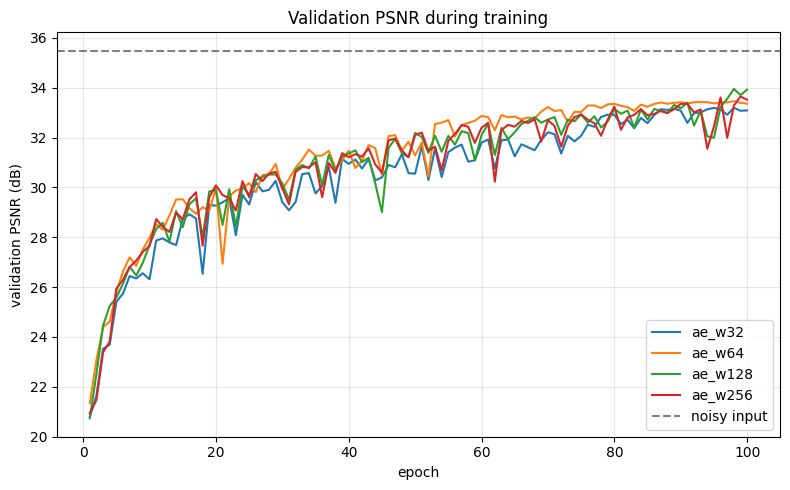

In [ ]:
import os, sys, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train
for mod in (ct_noise, ct_data, ct_models, ct_train):
    importlib.reload(mod)

device = torch.device('cuda')
data = ct_train.load_tensors(PROJECT, device)

for width in [128, 256, 64, 32]:
    ct_train.train_model(PROJECT, f'ae_w{width}', 'ae', width, data, loss_type='mse', epochs=100)


def summarize(names):
    rows = []
    for name in names:
        ck = torch.load(f'{PROJECT}/models/{name}.pt', map_location='cpu')
        h = pd.read_csv(f'{PROJECT}/results/history_{name}.csv')
        best = (h['val_loss'] - ck['best_val_loss']).abs().idxmin()
        rows.append({
            'model': name,
            'width': ck['width'],
            'params': ck['params'],
            'epochs_run': ck['epochs_run'],
            'best_epoch': int(h.loc[best, 'epoch']),
            'best_val_loss': ck['best_val_loss'],
            'val_psnr_dB': h.loc[best, 'val_psnr'],
            'last20_gain_dB': h['val_psnr'].iloc[-1] - h['val_psnr'].iloc[max(0, len(h) - 21)],
            'minutes': h['seconds'].sum() / 60,
        })
    return pd.DataFrame(rows)


names = [f'ae_w{w}' for w in [32, 64, 128, 256]]
table = summarize(names)
table.to_csv(f'{PROJECT}/results/width_sweep_training_summary.csv', index=False)
print(table.round(4).to_string(index=False))

vc, vn = data[1], data[2]
mse = ((vn.clamp(0, 1) - vc) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-12)
noisy_val_psnr = float((10 * torch.log10(1.0 / mse)).mean())

plt.figure(figsize=(8, 5))
for n in names:
    h = pd.read_csv(f'{PROJECT}/results/history_{n}.csv')
    plt.plot(h['epoch'], h['val_psnr'], label=n)
plt.axhline(noisy_val_psnr, color='gray', linestyle='--', label='noisy input')
plt.xlabel('epoch')
plt.ylabel('validation PSNR (dB)')
plt.title('Validation PSNR during training')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/width_sweep_training_curves.png', dpi=150)
plt.show()

In [ ]:
%%writefile /content/drive/MyDrive/ct_dae_project/ct_models.py
import torch
import torch.nn as nn


def down_block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


def up_block(cin, cout):
    return nn.Sequential(
        nn.ConvTranspose2d(cin, cout, 4, stride=2, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
    )


def conv_block(c):
    return nn.Sequential(
        nn.Conv2d(c, c, 3, padding=1, bias=False),
        nn.BatchNorm2d(c),
        nn.ReLU(inplace=True),
    )


class ConvAE(nn.Module):
    def __init__(self, width=128, variational=False, refine=False):
        super().__init__()
        self.width = width
        self.variational = variational
        enc = [down_block(1, 32)]
        if refine:
            enc.append(conv_block(32))
        enc.append(down_block(32, 64))
        if refine:
            enc.append(conv_block(64))
        enc += [down_block(64, 128), down_block(128, 256)]
        self.encoder = nn.Sequential(*enc)
        self.to_latent = nn.Conv2d(256, width, 3, padding=1)
        self.to_logvar = nn.Conv2d(256, width, 3, padding=1) if variational else None
        self.from_latent = nn.Sequential(
            nn.Conv2d(width, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
        )
        dec = [up_block(256, 128), up_block(128, 64)]
        if refine:
            dec.append(conv_block(64))
        dec.append(up_block(64, 32))
        if refine:
            dec.append(conv_block(32))
        dec.append(up_block(32, 32))
        if refine:
            dec.append(conv_block(32))
        self.decoder = nn.Sequential(*dec)
        self.head = nn.Conv2d(32, 1, 3, padding=1)

    def encode(self, x):
        h = self.encoder(x)
        mu = self.to_latent(h)
        if self.variational:
            return mu, self.to_logvar(h).clamp(-10.0, 10.0)
        return mu, None

    def decode(self, z):
        return torch.sigmoid(self.head(self.decoder(self.from_latent(z))))

    def forward(self, x):
        mu, logvar = self.encode(x)
        if self.variational and self.training:
            z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
            return self.decode(z), (mu, logvar)
        extra = (mu, logvar) if self.variational else None
        return self.decode(mu), extra


class DnCNN(nn.Module):
    def __init__(self, depth=17, channels=64):
        super().__init__()
        layers = [nn.Conv2d(1, channels, 3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [
                nn.Conv2d(channels, channels, 3, padding=1, bias=False),
                nn.BatchNorm2d(channels),
                nn.ReLU(inplace=True),
            ]
        layers.append(nn.Conv2d(channels, 1, 3, padding=1))
        self.body = nn.Sequential(*layers)

    def forward(self, x):
        return x - self.body(x), None


def build_model(kind, width=128):
    if kind == 'ae':
        return ConvAE(width, variational=False, refine=False)
    if kind == 'ae2':
        return ConvAE(width, variational=False, refine=True)
    if kind == 'vae':
        return ConvAE(width, variational=True, refine=False)
    if kind == 'vae2':
        return ConvAE(width, variational=True, refine=True)
    if kind == 'dncnn':
        return DnCNN()
    raise ValueError(kind)


def count_params(model):
    return sum(p.numel() for p in model.parameters())

Overwriting /content/drive/MyDrive/ct_dae_project/ct_models.py


In [ ]:
%%writefile /content/drive/MyDrive/ct_dae_project/ct_train.py
import os
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from ct_noise import add_noise_torch, sample_params_torch
from ct_data import augment, extract_tiles, reassemble
from ct_models import build_model, count_params


def gaussian_window(size=11, sigma=1.5):
    coords = torch.arange(size, dtype=torch.float32) - size // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return (g[:, None] * g[None, :]).view(1, 1, size, size)


def ssim_torch(x, y, window, c1=0.01 ** 2, c2=0.03 ** 2):
    mu_x = F.conv2d(x, window)
    mu_y = F.conv2d(y, window)
    sxx = F.conv2d(x * x, window) - mu_x ** 2
    syy = F.conv2d(y * y, window) - mu_y ** 2
    sxy = F.conv2d(x * y, window) - mu_x * mu_y
    s = ((2 * mu_x * mu_y + c1) * (2 * sxy + c2)) / ((mu_x ** 2 + mu_y ** 2 + c1) * (sxx + syy + c2))
    return s.mean(dim=(1, 2, 3))


def recon_loss(pred, target, loss_type, window, ssim_weight):
    pred = pred.float()
    mse = F.mse_loss(pred, target)
    if loss_type == 'mse_ssim':
        return mse + ssim_weight * (1.0 - ssim_torch(pred, target, window).mean()), mse
    return mse, mse


def kl_term(extra):
    mu, logvar = extra
    mu, logvar = mu.float(), logvar.float()
    return (-0.5 * (1.0 + logvar - mu.pow(2) - logvar.exp())).mean()


def load_tensors(project, device):
    train = torch.from_numpy(np.load(f'{project}/tiles/train_tiles.npy')).unsqueeze(1).to(device)
    val_clean = torch.from_numpy(np.load(f'{project}/tiles/val_tiles.npy')).unsqueeze(1).to(device)
    val_noisy = torch.from_numpy(np.load(f'{project}/tiles/val_tiles_noisy.npy')).unsqueeze(1).to(device)
    return train, val_clean, val_noisy


@torch.no_grad()
def validate(model, val_clean, val_noisy, loss_type, window, ssim_weight, bs=220):
    model.eval()
    total, psnr_sum, n = 0.0, 0.0, len(val_clean)
    for i in range(0, n, bs):
        c = val_clean[i:i + bs]
        out, _ = model(val_noisy[i:i + bs])
        loss, _ = recon_loss(out, c, loss_type, window, ssim_weight)
        mse_img = ((out.float().clamp(0, 1) - c) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-12)
        total += loss.item() * len(c)
        psnr_sum += (10 * torch.log10(1.0 / mse_img)).sum().item()
    return total / n, psnr_sum / n


def train_model(project, name, kind, width, data, loss_type='mse', epochs=100, lr=1e-3,
                batch_size=64, patience=12, lr_patience=4, ssim_weight=0.01,
                beta_max=1e-4, anneal_epochs=20, amp=True, skip_if_done=True, seed=42,
                schedule='plateau', eta_min=1e-5):
    ckpt_path = f'{project}/models/{name}.pt'
    if skip_if_done and os.path.exists(ckpt_path):
        print(f'{name}: checkpoint exists, skipping')
        return None
    os.makedirs(f'{project}/models', exist_ok=True)
    os.makedirs(f'{project}/results', exist_ok=True)

    train, val_clean, val_noisy = data
    device = train.device
    use_amp = bool(amp and device.type == 'cuda')
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = build_model(kind, width).to(device)
    n_params = count_params(model)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    is_vae = kind.startswith('vae')
    if schedule == 'cosine':
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=eta_min)
    else:
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=lr_patience)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    window = gaussian_window().to(device)
    monitor_from = anneal_epochs if is_vae else 1

    best, best_state, bad, history = float('inf'), None, 0, []
    n = len(train)
    t_start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        beta = beta_max * min(1.0, epoch / anneal_epochs) if is_vae else 0.0
        perm = torch.randperm(n, device=device)
        run, seen = 0.0, 0
        for i in range(0, n - batch_size + 1, batch_size):
            clean = augment(train[perm[i:i + batch_size]])
            n0, sigma = sample_params_torch(clean.shape[0], device)
            noisy = add_noise_torch(clean, n0, sigma)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out, extra = model(noisy)
            loss, _ = recon_loss(out, clean, loss_type, window, ssim_weight)
            if is_vae:
                loss = loss + beta * kl_term(extra)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            run += loss.item() * clean.shape[0]
            seen += clean.shape[0]

        val_loss, val_psnr = validate(model, val_clean, val_noisy, loss_type, window, ssim_weight)
        if schedule == 'cosine':
            sched.step()
        else:
            sched.step(val_loss)
        history.append({'epoch': epoch, 'train_loss': run / seen, 'val_loss': val_loss,
                        'val_psnr': val_psnr, 'lr': opt.param_groups[0]['lr'],
                        'beta': beta, 'seconds': time.time() - t0})
        flag = ''
        if epoch >= monitor_from:
            if val_loss < best - 1e-8:
                best, bad = val_loss, 0
                best_state = copy.deepcopy(model.state_dict())
                flag = ' *'
            else:
                bad += 1
        print(f'{name} ep {epoch:3d} train {run / seen:.6f} val {val_loss:.6f} '
              f'psnr {val_psnr:.2f} lr {opt.param_groups[0]["lr"]:.1e} {time.time() - t0:.1f}s{flag}')
        if bad >= patience:
            print(f'{name}: early stopping at epoch {epoch}')
            break

    if best_state is None:
        best_state = copy.deepcopy(model.state_dict())
        best = history[-1]['val_loss']
    model.load_state_dict(best_state)
    val_loss, val_psnr = validate(model, val_clean, val_noisy, loss_type, window, ssim_weight)

    torch.save({'state': best_state, 'kind': kind, 'width': width, 'loss_type': loss_type,
                'epochs_run': len(history), 'best_val_loss': best, 'params': n_params,
                'schedule': schedule}, ckpt_path)
    pd.DataFrame(history).to_csv(f'{project}/results/history_{name}.csv', index=False)
    summary = {'name': name, 'kind': kind, 'width': width, 'loss_type': loss_type, 'schedule': schedule,
               'params': n_params, 'epochs_run': len(history), 'best_val_loss': best,
               'val_psnr': val_psnr, 'train_minutes': (time.time() - t_start) / 60,
               'sec_per_epoch': float(np.mean([h['seconds'] for h in history]))}
    print(summary)
    return summary


def load_model(project, name, device):
    ck = torch.load(f'{project}/models/{name}.pt', map_location=device)
    model = build_model(ck['kind'], ck['width']).to(device)
    model.load_state_dict(ck['state'])
    model.eval()
    return model


@torch.no_grad()
def predict_slices(model, slices, device, stride=128, batch_size=256):
    model.eval()
    per_slice = [extract_tiles(s, 128, stride) for s in slices]
    k = len(per_slice[0])
    tiles = torch.from_numpy(np.concatenate(per_slice)).unsqueeze(1).to(device)
    outs = []
    for i in range(0, len(tiles), batch_size):
        out, _ = model(tiles[i:i + batch_size])
        outs.append(out.float().cpu())
    pred = torch.cat(outs).squeeze(1).numpy()
    return np.stack([reassemble(pred[j * k:(j + 1) * k], slices[j].shape, 128, stride)
                     for j in range(len(slices))])

Overwriting /content/drive/MyDrive/ct_dae_project/ct_train.py


pilot_ae_cos ep   1 train 0.026710 val 0.009970 psnr 20.73 lr 1.0e-03 1.9s *
pilot_ae_cos ep   2 train 0.007771 val 0.007007 psnr 22.51 lr 1.0e-03 1.8s *
pilot_ae_cos ep   3 train 0.005742 val 0.004739 psnr 24.46 lr 9.9e-04 1.8s *
pilot_ae_cos ep   4 train 0.004870 val 0.004110 psnr 25.18 lr 9.8e-04 1.8s *
pilot_ae_cos ep   5 train 0.004059 val 0.003568 psnr 25.92 lr 9.8e-04 1.8s *
pilot_ae_cos ep   6 train 0.003618 val 0.003304 psnr 26.15 lr 9.7e-04 1.8s *
pilot_ae_cos ep   7 train 0.003142 val 0.002946 psnr 26.71 lr 9.5e-04 1.8s *
pilot_ae_cos ep   8 train 0.002784 val 0.002720 psnr 26.91 lr 9.4e-04 1.8s *
pilot_ae_cos ep   9 train 0.002557 val 0.002509 psnr 27.23 lr 9.2e-04 1.8s *
pilot_ae_cos ep  10 train 0.002344 val 0.002215 psnr 27.88 lr 9.1e-04 1.8s *
pilot_ae_cos ep  11 train 0.002167 val 0.002108 psnr 28.07 lr 8.9e-04 1.8s *
pilot_ae_cos ep  12 train 0.001981 val 0.001889 psnr 28.63 lr 8.7e-04 1.8s *
pilot_ae_cos ep  13 train 0.001888 val 0.001961 psnr 28.25 lr 8.4e-04 1.8s
p

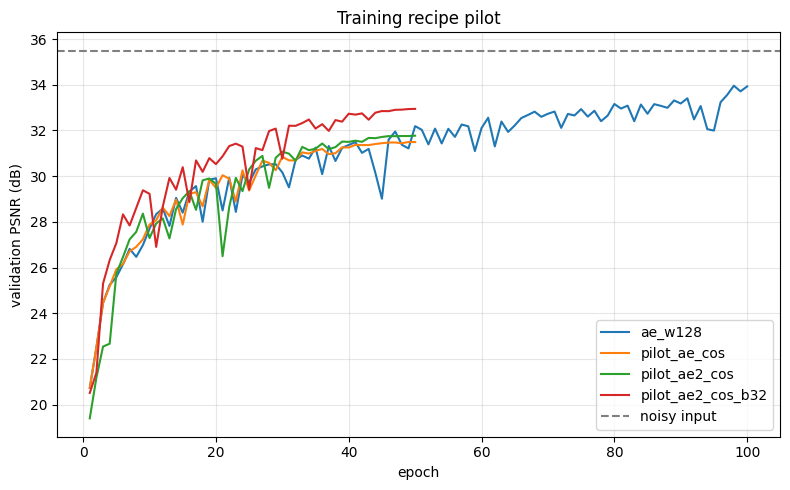

In [ ]:
import os, sys, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train
for mod in (ct_noise, ct_data, ct_models, ct_train):
    importlib.reload(mod)

device = torch.device('cuda')
data = ct_train.load_tensors(PROJECT, device)

runs = [('pilot_ae_cos', 'ae', 64), ('pilot_ae2_cos', 'ae2', 64), ('pilot_ae2_cos_b32', 'ae2', 32)]
for name, kind, bs in runs:
    ct_train.train_model(PROJECT, name, kind, 128, data, epochs=50, batch_size=bs,
                         patience=50, schedule='cosine')

names = ['ae_w128'] + [r[0] for r in runs]
rows = []
for n in names:
    h = pd.read_csv(f'{PROJECT}/results/history_{n}.csv')
    ck = torch.load(f'{PROJECT}/models/{n}.pt', map_location='cpu')
    best = h['val_loss'].idxmin()
    rows.append({
        'run': n,
        'kind': ck['kind'],
        'schedule': ck.get('schedule', 'plateau'),
        'params': ck['params'],
        'epochs': len(h),
        'psnr_ep10': h['val_psnr'].iloc[9],
        'psnr_ep25': h['val_psnr'].iloc[24],
        'best_psnr_dB': h.loc[best, 'val_psnr'],
        'sec_per_epoch': h['seconds'].mean(),
    })
table = pd.DataFrame(rows)
table.to_csv(f'{PROJECT}/results/recipe_pilot_summary.csv', index=False)
print(table.round(2).to_string(index=False))

vc, vn = data[1], data[2]
mse = ((vn.clamp(0, 1) - vc) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-12)
noisy_val_psnr = float((10 * torch.log10(1.0 / mse)).mean())
print('noisy input validation PSNR:', round(noisy_val_psnr, 2), 'dB')

plt.figure(figsize=(8, 5))
for n in names:
    h = pd.read_csv(f'{PROJECT}/results/history_{n}.csv')
    plt.plot(h['epoch'], h['val_psnr'], label=n)
plt.axhline(noisy_val_psnr, color='gray', linestyle='--', label='noisy input')
plt.xlabel('epoch')
plt.ylabel('validation PSNR (dB)')
plt.title('Training recipe pilot')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/recipe_pilot_curves.png', dpi=150)
plt.show()

noisy input validation PSNR: 35.49 dB
pilot2_b16_lr1e-3 ep   1 train 0.012653 val 0.004676 psnr 24.64 lr 1.0e-03 2.6s *
pilot2_b16_lr1e-3 ep   2 train 0.004543 val 0.003628 psnr 25.76 lr 1.0e-03 2.4s *
pilot2_b16_lr1e-3 ep   3 train 0.003266 val 0.002608 psnr 27.04 lr 9.9e-04 2.4s *
pilot2_b16_lr1e-3 ep   4 train 0.002581 val 0.003036 psnr 25.97 lr 9.8e-04 2.4s
pilot2_b16_lr1e-3 ep   5 train 0.002189 val 0.001823 psnr 28.70 lr 9.8e-04 2.4s *
pilot2_b16_lr1e-3 ep   6 train 0.001910 val 0.001696 psnr 29.05 lr 9.7e-04 2.5s *
pilot2_b16_lr1e-3 ep   7 train 0.001830 val 0.001646 psnr 29.13 lr 9.5e-04 2.5s *
pilot2_b16_lr1e-3 ep   8 train 0.001656 val 0.001630 psnr 28.91 lr 9.4e-04 2.5s *
pilot2_b16_lr1e-3 ep   9 train 0.001513 val 0.001354 psnr 30.01 lr 9.2e-04 2.5s *
pilot2_b16_lr1e-3 ep  10 train 0.001495 val 0.001452 psnr 29.67 lr 9.1e-04 2.4s
pilot2_b16_lr1e-3 ep  11 train 0.001386 val 0.001377 psnr 29.85 lr 8.9e-04 2.4s
pilot2_b16_lr1e-3 ep  12 train 0.001364 val 0.001342 psnr 29.73 lr

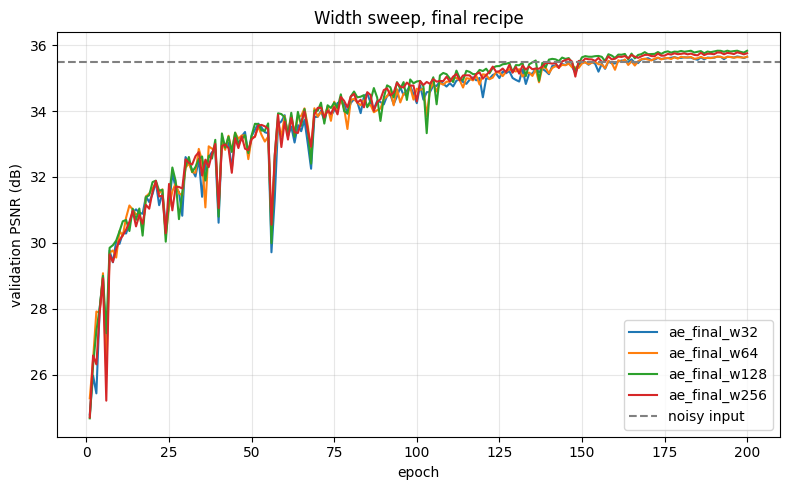

In [ ]:
import os, sys, json, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train
for mod in (ct_noise, ct_data, ct_models, ct_train):
    importlib.reload(mod)

PILOT_EPOCHS = 50
FINAL_EPOCHS = 200
GATE_MARGIN_DB = 0.5

device = torch.device('cuda')
data = ct_train.load_tensors(PROJECT, device)

vc, vn = data[1], data[2]
mse = ((vn.clamp(0, 1) - vc) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-12)
noisy_val_psnr = float((10 * torch.log10(1.0 / mse)).mean())
print('noisy input validation PSNR:', round(noisy_val_psnr, 2), 'dB')


def run_info(name):
    h = pd.read_csv(f'{PROJECT}/results/history_{name}.csv')
    psnr = float(h.loc[h['val_loss'].idxmin(), 'val_psnr'])
    return h, (psnr if np.isfinite(psnr) else -1.0)


variants = [('b16_lr1e-3', 16, 1e-3), ('b16_lr3e-3', 16, 3e-3), ('b8_lr1e-3', 8, 1e-3)]
for tag, bs, lr in variants:
    ct_train.train_model(PROJECT, f'pilot2_{tag}', 'ae', 128, data, epochs=PILOT_EPOCHS,
                         batch_size=bs, lr=lr, patience=PILOT_EPOCHS, schedule='cosine')

pilot_rows = []
for tag, bs, lr in variants:
    h, psnr = run_info(f'pilot2_{tag}')
    pilot_rows.append({'variant': tag, 'batch_size': bs, 'lr': lr,
                       'best_psnr_dB': psnr, 'sec_per_epoch': h['seconds'].mean()})
pilot = pd.DataFrame(pilot_rows)
pilot.to_csv(f'{PROJECT}/results/recipe_pilot2_summary.csv', index=False)
print(pilot.round(3).to_string(index=False))

winner = pilot.loc[pilot['best_psnr_dB'].idxmax()]
batch_size, lr = int(winner['batch_size']), float(winner['lr'])
print('selected recipe:', winner['variant'])
with open(f'{PROJECT}/results/final_recipe.json', 'w') as f:
    json.dump({'kind': 'ae', 'batch_size': batch_size, 'lr': lr,
               'epochs': FINAL_EPOCHS, 'schedule': 'cosine'}, f, indent=2)

proceed = True
for width in [128, 256, 64, 32]:
    if not proceed:
        break
    name = f'ae_final_w{width}'
    ct_train.train_model(PROJECT, name, 'ae', width, data, epochs=FINAL_EPOCHS,
                         batch_size=batch_size, lr=lr, patience=60, schedule='cosine')
    if width == 128:
        _, psnr = run_info(name)
        if psnr < noisy_val_psnr - GATE_MARGIN_DB:
            print(f'width 128 reached {psnr:.2f} dB, below the noisy input ({noisy_val_psnr:.2f} dB); '
                  'stopping before the other widths')
            proceed = False

names = [f'ae_final_w{w}' for w in [32, 64, 128, 256]
         if os.path.exists(f'{PROJECT}/models/ae_final_w{w}.pt')]
rows = []
for n in names:
    ck = torch.load(f'{PROJECT}/models/{n}.pt', map_location='cpu')
    h, psnr = run_info(n)
    rows.append({
        'model': n,
        'width': ck['width'],
        'params': ck['params'],
        'epochs_run': ck['epochs_run'],
        'best_epoch': int(h.loc[h['val_loss'].idxmin(), 'epoch']),
        'val_psnr_dB': psnr,
        'last20_gain_dB': h['val_psnr'].iloc[-1] - h['val_psnr'].iloc[max(0, len(h) - 21)],
        'minutes': h['seconds'].sum() / 60,
    })
table = pd.DataFrame(rows)
table.to_csv(f'{PROJECT}/results/width_sweep_final_summary.csv', index=False)
print(table.round(3).to_string(index=False))

plt.figure(figsize=(8, 5))
for n in names:
    h = pd.read_csv(f'{PROJECT}/results/history_{n}.csv')
    plt.plot(h['epoch'], h['val_psnr'], label=n)
plt.axhline(noisy_val_psnr, color='gray', linestyle='--', label='noisy input')
plt.xlabel('epoch')
plt.ylabel('validation PSNR (dB)')
plt.title('Width sweep, final recipe')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/width_sweep_final_curves.png', dpi=150)
plt.show()

In [ ]:
import os, sys, json, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train
for mod in (ct_noise, ct_data, ct_models, ct_train):
    importlib.reload(mod)

with open(f'{PROJECT}/results/final_recipe.json') as f:
    recipe = json.load(f)
print('recipe in use:', recipe)
batch_size, lr, epochs = recipe['batch_size'], recipe['lr'], recipe['epochs']

device = torch.device('cuda')
data = ct_train.load_tensors(PROJECT, device)

jobs = [
    ('dncnn', 'dncnn', 0, 'mse', dict(epochs=60, patience=30, lr=min(lr, 1e-3))),
    ('vae_w128', 'vae', 128, 'mse', dict(epochs=epochs, patience=60, lr=lr)),
    ('ae_ssim_w128', 'ae', 128, 'mse_ssim', dict(epochs=epochs, patience=60, lr=lr, ssim_weight=0.005)),
]
for name, kind, width, loss_type, kw in jobs:
    ct_train.train_model(PROJECT, name, kind, width, data, loss_type=loss_type,
                         batch_size=batch_size, schedule='cosine', **kw)


def run_info(name):
    h = pd.read_csv(f'{PROJECT}/results/history_{name}.csv')
    best = h['val_loss'].idxmin()
    return h, best


names = ['ae_final_w128', 'ae_ssim_w128', 'vae_w128', 'dncnn']
rows = []
for n in names:
    ck = torch.load(f'{PROJECT}/models/{n}.pt', map_location='cpu')
    h, best = run_info(n)
    rows.append({
        'model': n,
        'kind': ck['kind'],
        'loss': ck['loss_type'],
        'params': ck['params'],
        'epochs_run': ck['epochs_run'],
        'best_epoch': int(h.loc[best, 'epoch']),
        'val_psnr_dB': h.loc[best, 'val_psnr'],
        'sec_per_epoch': h['seconds'].mean(),
        'minutes': h['seconds'].sum() / 60,
    })
table = pd.DataFrame(rows)
table.to_csv(f'{PROJECT}/results/stage2_training_summary.csv', index=False)
print(table.round(3).to_string(index=False))

vc, vn = data[1], data[2]
mse = ((vn.clamp(0, 1) - vc) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-12)
noisy_val_psnr = float((10 * torch.log10(1.0 / mse)).mean())

plt.figure(figsize=(8, 5))
for n in names:
    h = pd.read_csv(f'{PROJECT}/results/history_{n}.csv')
    plt.plot(h['epoch'], h['val_psnr'], label=n)
plt.axhline(noisy_val_psnr, color='gray', linestyle='--', label='noisy input')
plt.xlabel('epoch')
plt.ylabel('validation PSNR (dB)')
plt.title('Baseline and variants, validation PSNR')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/stage2_training_curves.png', dpi=150)
plt.show()

recipe in use: {'kind': 'ae', 'batch_size': 8, 'lr': 0.001, 'epochs': 200, 'schedule': 'cosine'}
dncnn ep   1 train 0.004828 val 0.000425 psnr 35.39 lr 1.0e-03 25.7s *
dncnn ep   2 train 0.000294 val 0.000177 psnr 38.65 lr 1.0e-03 26.0s *
dncnn ep   3 train 0.000148 val 0.000124 psnr 40.20 lr 9.9e-04 26.4s *
dncnn ep   4 train 0.000130 val 0.000118 psnr 40.40 lr 9.9e-04 26.2s *
dncnn ep   5 train 0.000119 val 0.000109 psnr 40.76 lr 9.8e-04 26.1s *
dncnn ep   6 train 0.000113 val 0.000108 psnr 40.68 lr 9.8e-04 26.3s *
dncnn ep   7 train 0.000114 val 0.000096 psnr 41.38 lr 9.7e-04 26.3s *


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, glob
PROJECT = '/content/drive/MyDrive/ct_dae_project'
print(sorted(os.path.basename(p) for p in glob.glob(f'{PROJECT}/models/*.pt')))

['ae_final_w128.pt', 'ae_final_w256.pt', 'ae_final_w32.pt', 'ae_final_w64.pt', 'ae_w128.pt', 'ae_w256.pt', 'ae_w32.pt', 'ae_w64.pt', 'pilot2_b16_lr1e-3.pt', 'pilot2_b16_lr3e-3.pt', 'pilot2_b8_lr1e-3.pt', 'pilot_ae2_cos.pt', 'pilot_ae2_cos_b32.pt', 'pilot_ae_cos.pt']


recipe in use: {'kind': 'ae', 'batch_size': 8, 'lr': 0.001, 'epochs': 200, 'schedule': 'cosine'}
dncnn ep   1 train 0.004828 val 0.000425 psnr 35.39 lr 1.0e-03 28.5s *
dncnn ep   2 train 0.000294 val 0.000177 psnr 38.65 lr 1.0e-03 25.3s *
dncnn ep   3 train 0.000148 val 0.000124 psnr 40.20 lr 9.9e-04 25.6s *
dncnn ep   4 train 0.000130 val 0.000118 psnr 40.40 lr 9.9e-04 25.9s *
dncnn ep   5 train 0.000119 val 0.000109 psnr 40.76 lr 9.8e-04 26.2s *
dncnn ep   6 train 0.000113 val 0.000108 psnr 40.68 lr 9.8e-04 26.7s *
dncnn ep   7 train 0.000114 val 0.000096 psnr 41.38 lr 9.7e-04 27.0s *
dncnn ep   8 train 0.000115 val 0.000106 psnr 40.45 lr 9.6e-04 27.2s
dncnn ep   9 train 0.000115 val 0.000095 psnr 41.37 lr 9.5e-04 27.7s *
dncnn ep  10 train 0.000109 val 0.000089 psnr 41.43 lr 9.3e-04 27.8s *
dncnn ep  11 train 0.000104 val 0.000097 psnr 41.82 lr 9.2e-04 27.9s
dncnn ep  12 train 0.000096 val 0.000112 psnr 40.06 lr 9.1e-04 27.9s
dncnn ep  13 train 0.000096 val 0.000092 psnr 41.41 lr 8.

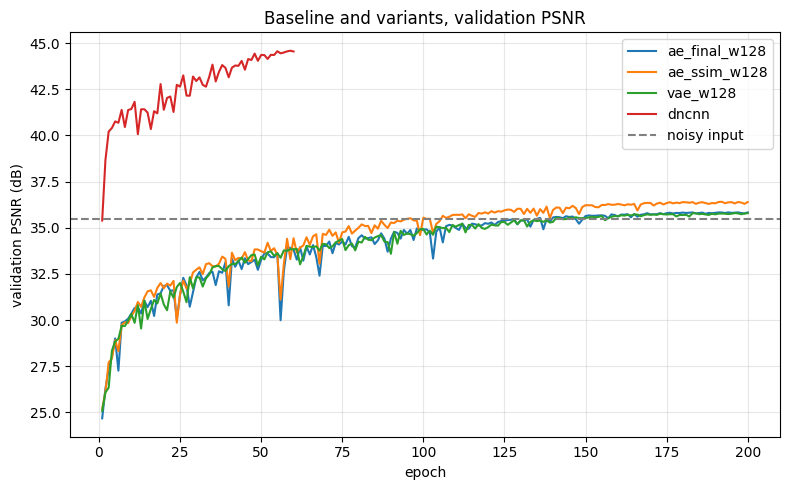

In [ ]:
import os, sys, json, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train
for mod in (ct_noise, ct_data, ct_models, ct_train):
    importlib.reload(mod)

with open(f'{PROJECT}/results/final_recipe.json') as f:
    recipe = json.load(f)
print('recipe in use:', recipe)
batch_size, lr, epochs = recipe['batch_size'], recipe['lr'], recipe['epochs']

device = torch.device('cuda')
data = ct_train.load_tensors(PROJECT, device)

jobs = [
    ('dncnn', 'dncnn', 0, 'mse', dict(epochs=60, patience=30, lr=min(lr, 1e-3))),
    ('vae_w128', 'vae', 128, 'mse', dict(epochs=epochs, patience=60, lr=lr)),
    ('ae_ssim_w128', 'ae', 128, 'mse_ssim', dict(epochs=epochs, patience=60, lr=lr, ssim_weight=0.005)),
]
for name, kind, width, loss_type, kw in jobs:
    ct_train.train_model(PROJECT, name, kind, width, data, loss_type=loss_type,
                         batch_size=batch_size, schedule='cosine', **kw)


def run_info(name):
    h = pd.read_csv(f'{PROJECT}/results/history_{name}.csv')
    best = h['val_loss'].idxmin()
    return h, best


names = ['ae_final_w128', 'ae_ssim_w128', 'vae_w128', 'dncnn']
rows = []
for n in names:
    ck = torch.load(f'{PROJECT}/models/{n}.pt', map_location='cpu')
    h, best = run_info(n)
    rows.append({
        'model': n,
        'kind': ck['kind'],
        'loss': ck['loss_type'],
        'params': ck['params'],
        'epochs_run': ck['epochs_run'],
        'best_epoch': int(h.loc[best, 'epoch']),
        'val_psnr_dB': h.loc[best, 'val_psnr'],
        'sec_per_epoch': h['seconds'].mean(),
        'minutes': h['seconds'].sum() / 60,
    })
table = pd.DataFrame(rows)
table.to_csv(f'{PROJECT}/results/stage2_training_summary.csv', index=False)
print(table.round(3).to_string(index=False))

vc, vn = data[1], data[2]
mse = ((vn.clamp(0, 1) - vc) ** 2).mean(dim=(1, 2, 3)).clamp_min(1e-12)
noisy_val_psnr = float((10 * torch.log10(1.0 / mse)).mean())

plt.figure(figsize=(8, 5))
for n in names:
    h = pd.read_csv(f'{PROJECT}/results/history_{n}.csv')
    plt.plot(h['epoch'], h['val_psnr'], label=n)
plt.axhline(noisy_val_psnr, color='gray', linestyle='--', label='noisy input')
plt.xlabel('epoch')
plt.ylabel('validation PSNR (dB)')
plt.title('Baseline and variants, validation PSNR')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/stage2_training_curves.png', dpi=150)
plt.show()

gaussian sigma search: {0.3: 36.177, 0.4: 37.016, 0.5: 36.794, 0.6: 35.398, 0.7: 34.044} -> best 0.4
ae_w32 evaluated
ae_w64 evaluated
ae_w128 evaluated
ae_w256 evaluated
ae_ssim_w128 evaluated
vae_w128 evaluated
dncnn evaluated

clean slices Laplacian variance: 0.01136

mixed-dose test set, full slices
              PSNR_all  SSIM_all  MSE_all  LapVar_all  PSNR_real  PSNR_phantom  SSIM_real  SSIM_phantom
method                                                                                                 
noisy_input    35.5591    0.7565   0.0003      0.0174    35.4564       35.8328     0.7999        0.6406
gaussian       36.5247    0.8020   0.0003      0.0124    36.3976       36.8637     0.8383        0.7052
median         35.0319    0.9053   0.0004      0.0074    32.4825       41.8300     0.9068        0.9012
nlm            42.3245    0.9693   0.0001      0.0112    40.3529       47.5819     0.9620        0.9890
ae_w32         34.8579    0.9362   0.0004      0.0076    32.9956       

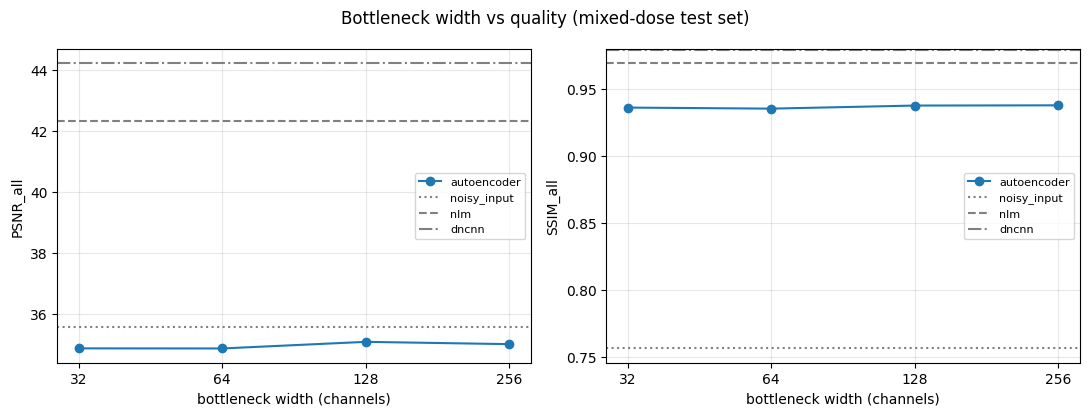

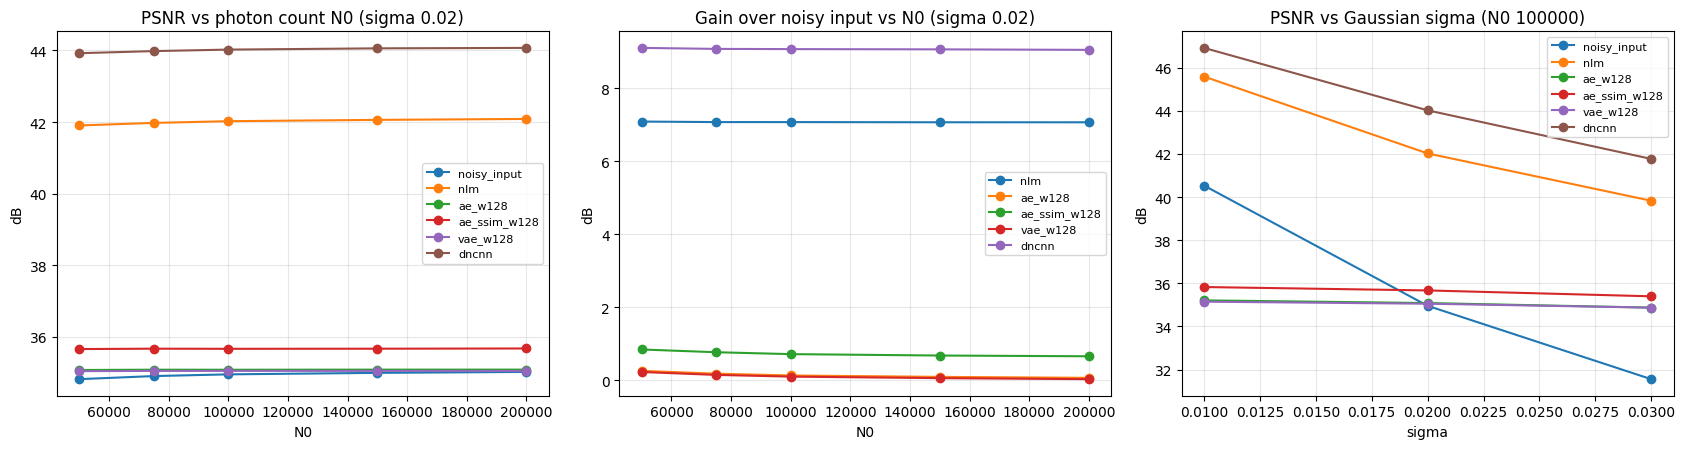

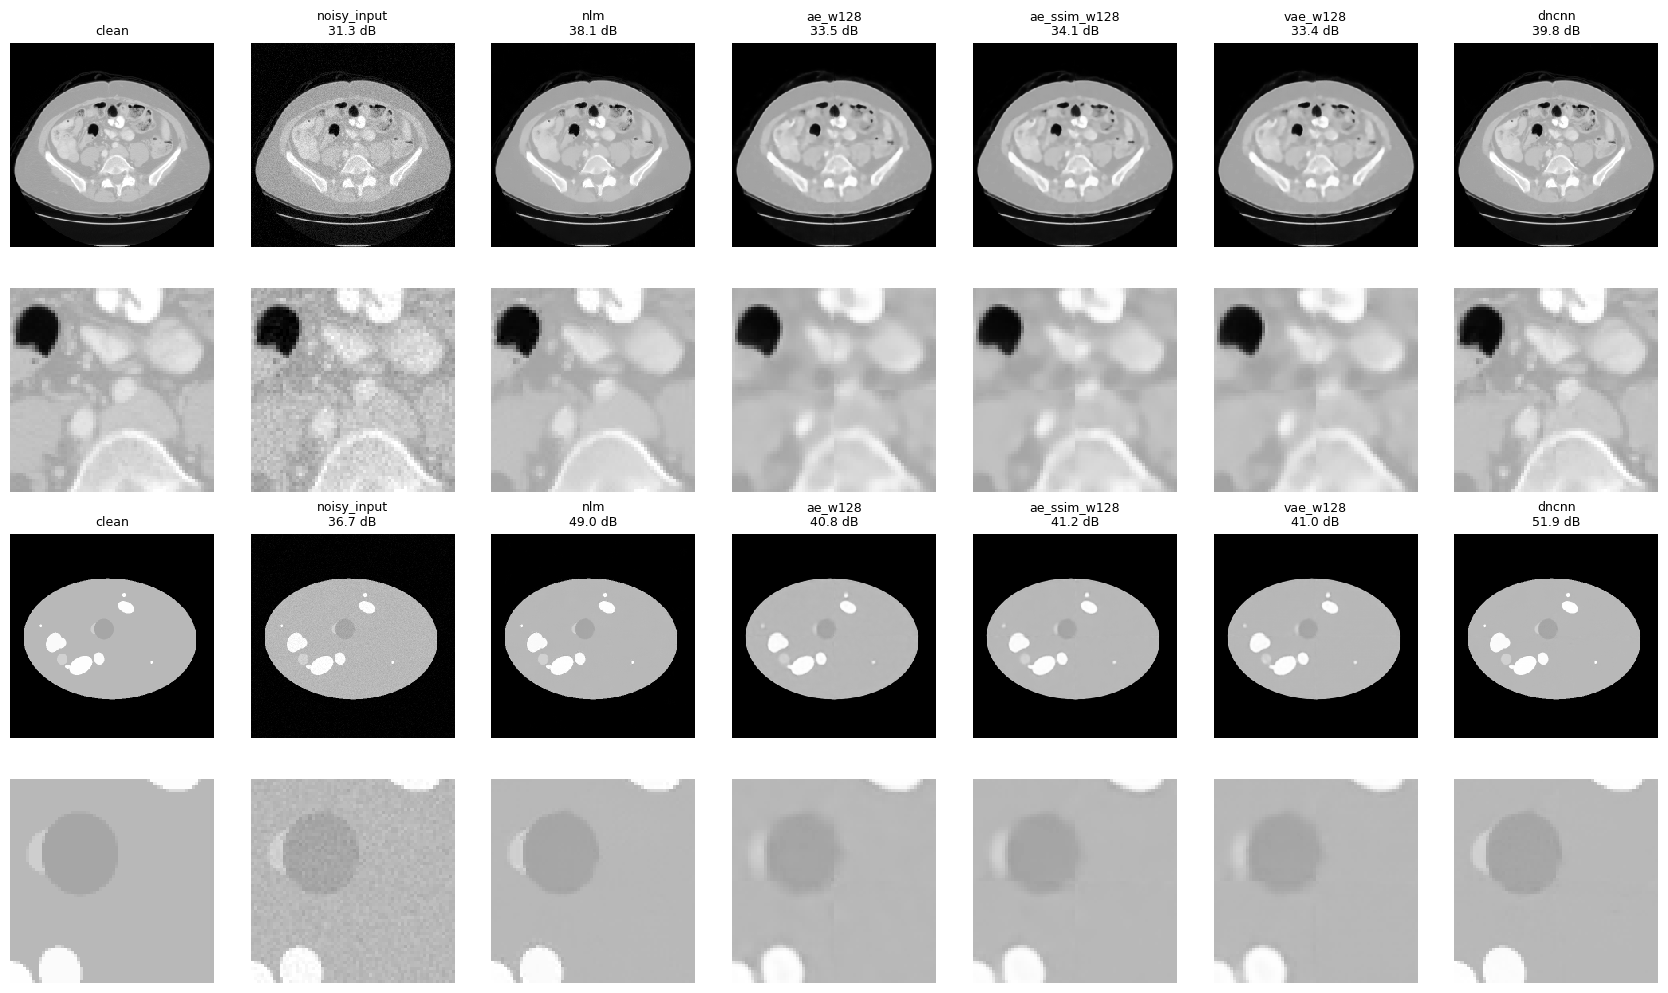

In [ ]:
import os, sys, json, time, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train, ct_metrics
for mod in (ct_noise, ct_data, ct_models, ct_train, ct_metrics):
    importlib.reload(mod)
from ct_metrics import evaluate, psnr_each, lapvar_each, gaussian_filter_batch

device = torch.device('cuda')
os.makedirs(f'{PROJECT}/results/preds', exist_ok=True)

clean = np.load(f'{PROJECT}/testsets/clean.npy')
labels = np.load(f'{PROJECT}/testsets/labels.npy')
with open(f'{PROJECT}/testsets/conditions.json') as f:
    conditions = json.load(f)
SEL = np.arange(len(clean))
clean, labels = clean[SEL], labels[SEL]

val_clean = np.load(f'{PROJECT}/tiles/val_tiles.npy')
val_noisy = np.load(f'{PROJECT}/tiles/val_tiles_noisy.npy')
pick = np.random.RandomState(7).choice(len(val_clean), 80, replace=False)
vc, vn = val_clean[pick], val_noisy[pick]
grid = [0.3, 0.4, 0.5, 0.6, 0.7]
scores = {s: float(psnr_each(vc, np.clip(gaussian_filter_batch(vn, s), 0, 1)).mean()) for s in grid}
best_sigma = max(scores, key=scores.get)
print('gaussian sigma search:', {k: round(v, 3) for k, v in scores.items()}, '-> best', best_sigma)

classical = pd.read_csv(f'{PROJECT}/results/classical_metrics.csv')
classical = classical[classical.method != 'gaussian']
g_rows = []
for cond in conditions:
    noisy = np.load(f'{PROJECT}/testsets/noisy_{cond}.npy')[SEL]
    pred = np.clip(gaussian_filter_batch(noisy, best_sigma), 0, 1)
    m, _ = evaluate(clean, pred, labels)
    g_rows.append({'condition': cond, 'method': 'gaussian', 'seconds': 0.0, **m})
    if cond == 'mixed':
        np.save(f'{PROJECT}/results/preds/gaussian_mixed.npy', pred.astype(np.float32))
classical = pd.concat([classical, pd.DataFrame(g_rows)], ignore_index=True)
classical['stride'] = 'n/a'
with open(f'{PROJECT}/results/classical_params.json') as f:
    params = json.load(f)
params['gaussian'] = best_sigma
with open(f'{PROJECT}/results/classical_params.json', 'w') as f:
    json.dump(params, f, indent=2)

deep = {
    'ae_w32': 'ae_final_w32',
    'ae_w64': 'ae_final_w64',
    'ae_w128': 'ae_final_w128',
    'ae_w256': 'ae_final_w256',
    'ae_ssim_w128': 'ae_ssim_w128',
    'vae_w128': 'vae_w128',
    'dncnn': 'dncnn',
}
rows = []
preds_mixed = {}
for label, ckpt in deep.items():
    model = ct_train.load_model(PROJECT, ckpt, device)
    for cond in conditions:
        noisy = np.load(f'{PROJECT}/testsets/noisy_{cond}.npy')[SEL]
        for stride in ([128, 64] if cond == 'mixed' else [128]):
            pred = np.clip(ct_train.predict_slices(model, noisy, device, stride=stride), 0.0, 1.0)
            m, _ = evaluate(clean, pred, labels)
            rows.append({'condition': cond, 'method': label, 'stride': str(stride), **m})
            if cond == 'mixed' and stride == 128:
                preds_mixed[label] = pred
                np.save(f'{PROJECT}/results/preds/{label}_mixed.npy', pred.astype(np.float32))
    print(label, 'evaluated')
deep_df = pd.DataFrame(rows)
deep_df.to_csv(f'{PROJECT}/results/deep_metrics.csv', index=False)

all_df = pd.concat([classical, deep_df], ignore_index=True)
all_df.to_csv(f'{PROJECT}/results/all_metrics.csv', index=False)

order = ['noisy_input', 'gaussian', 'median', 'nlm', 'ae_w32', 'ae_w64', 'ae_w128', 'ae_w256',
         'ae_ssim_w128', 'vae_w128', 'dncnn']
base = all_df[all_df.stride.isin(['n/a', '128'])]
main = base[base.condition == 'mixed'].set_index('method').loc[order]
cols = ['PSNR_all', 'SSIM_all', 'MSE_all', 'LapVar_all', 'PSNR_real', 'PSNR_phantom', 'SSIM_real', 'SSIM_phantom']
main[cols].to_csv(f'{PROJECT}/results/main_results_mixed.csv')
print('\nclean slices Laplacian variance:', round(float(lapvar_each(clean).mean()), 5))
print('\nmixed-dose test set, full slices')
print(main[cols].round(4).to_string())

print('\ntiling comparison on the mixed-dose set (stride 128 = no overlap, 64 = blended overlap)')
tile_cmp = deep_df[deep_df.condition == 'mixed'].pivot(index='method', columns='stride',
                                                       values=['PSNR_all', 'SSIM_all']).round(4)
print(tile_cmp.to_string())

widths = [32, 64, 128, 256]
sub = main.loc[[f'ae_w{w}' for w in widths]]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, metric in zip(ax, ['PSNR_all', 'SSIM_all']):
    a.plot(widths, sub[metric].values, 'o-', label='autoencoder')
    for name, style in [('noisy_input', ':'), ('nlm', '--'), ('dncnn', '-.')]:
        a.axhline(main.loc[name, metric], linestyle=style, color='gray', label=name)
    a.set_xscale('log', base=2)
    a.set_xticks(widths)
    a.set_xticklabels(widths)
    a.set_xlabel('bottleneck width (channels)')
    a.set_ylabel(metric)
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
plt.suptitle('Bottleneck width vs quality (mixed-dose test set)')
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/width_vs_quality.png', dpi=150)
plt.show()

methods = ['noisy_input', 'nlm', 'ae_w128', 'ae_ssim_w128', 'vae_w128', 'dncnn']
n0_vals = [5e4, 7.5e4, 1e5, 1.5e5, 2e5]
n0_conds = [f'N0_{int(n)}_sigma_0.02' for n in n0_vals]
sig_vals = [0.01, 0.02, 0.03]
sig_conds = ['N0_100000_sigma_0.01', 'N0_100000_sigma_0.02', 'N0_100000_sigma_0.03']


def curve(method, conds):
    d = base[base.method == method].set_index('condition')
    return d.loc[conds, 'PSNR_all'].values


fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for m in methods:
    ax[0].plot(n0_vals, curve(m, n0_conds), 'o-', label=m)
    ax[2].plot(sig_vals, curve(m, sig_conds), 'o-', label=m)
    if m != 'noisy_input':
        ax[1].plot(n0_vals, curve(m, n0_conds) - curve('noisy_input', n0_conds), 'o-', label=m)
ax[0].set_title('PSNR vs photon count N0 (sigma 0.02)')
ax[1].set_title('Gain over noisy input vs N0 (sigma 0.02)')
ax[2].set_title('PSNR vs Gaussian sigma (N0 100000)')
ax[0].set_xlabel('N0')
ax[1].set_xlabel('N0')
ax[2].set_xlabel('sigma')
for a in ax:
    a.set_ylabel('dB')
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/dose_robustness.png', dpi=150)
plt.show()

noisy_mixed = np.load(f'{PROJECT}/testsets/noisy_mixed.npy')[SEL]
imgs = {'clean': clean, 'noisy_input': np.clip(noisy_mixed, 0, 1),
        'nlm': np.load(f'{PROJECT}/results/preds/nlm_mixed.npy')[SEL]}
for k in ['ae_w128', 'ae_ssim_w128', 'vae_w128', 'dncnn']:
    imgs[k] = preds_mixed[k]
order_show = ['clean', 'noisy_input', 'nlm', 'ae_w128', 'ae_ssim_w128', 'vae_w128', 'dncnn']
real_idx = np.where(labels < 0)[0]
ph_idx = np.where(labels >= 0)[0]
ri, pi = real_idx[len(real_idx) // 3], ph_idx[len(ph_idx) // 3]

fig, axes = plt.subplots(4, 7, figsize=(17, 10))
for c, key in enumerate(order_show):
    for r, (idx, crop) in enumerate([(ri, False), (ri, True), (pi, False), (pi, True)]):
        im = imgs[key][idx]
        if crop:
            im = im[96:160, 96:160]
        axes[r, c].imshow(im, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        axes[r, c].axis('off')
        if r in (0, 2):
            title = key if key == 'clean' else f'{key}\n{psnr_each(clean[[idx]], imgs[key][[idx]])[0]:.1f} dB'
            axes[r, c].set_title(title, fontsize=9)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/visual_comparison.png', dpi=150)
plt.show()

Mounted at /content/drive
phantoms used: 90 | per class: [18, 18, 18, 18, 18]
ae_w32 done
ae_w64 done
ae_w128 done
ae_w256 done
ae_ssim_w128 done
vae_w128 done
              model  latent_dim  silhouette_latent  silhouette_pca2  silhouette_tsne2
             ae_w32          32             -0.009           -0.024            -0.054
             ae_w64          64             -0.003           -0.010             0.015
            ae_w128         128              0.008            0.024            -0.007
            ae_w256         256              0.015            0.005            -0.062
       ae_ssim_w128         128              0.006           -0.015            -0.084
           vae_w128         128              0.014           -0.042             0.013
intensity_histogram          32              0.314            0.026             0.698


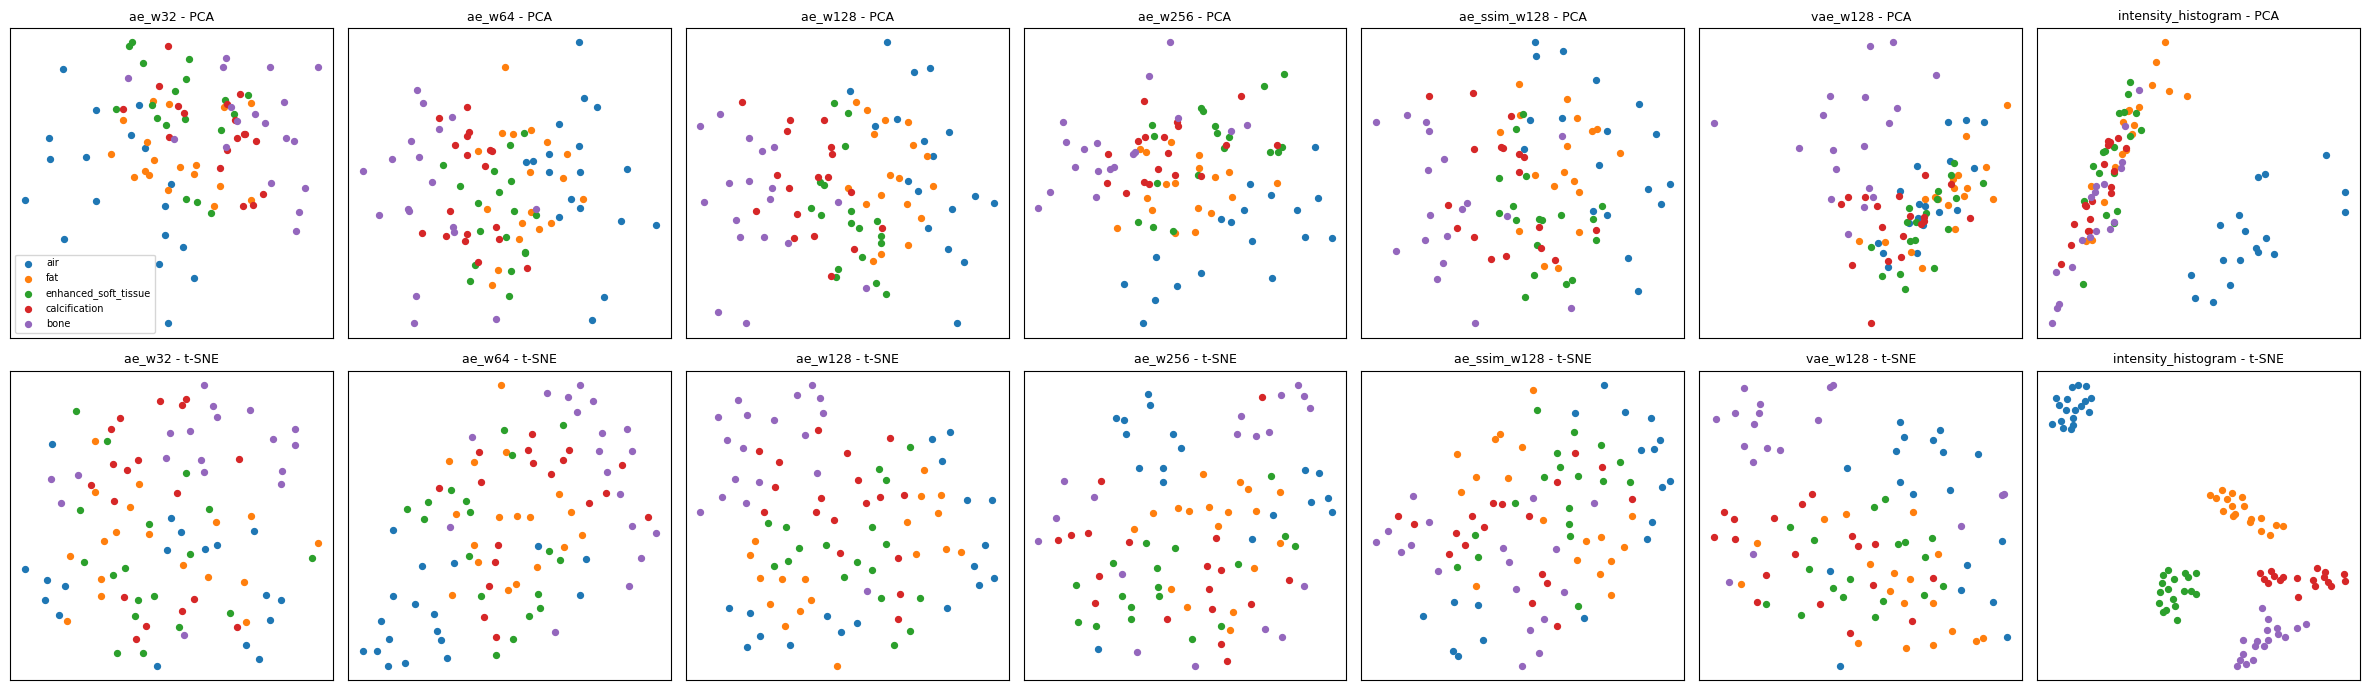

In [ ]:
import os, sys, json, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train
for mod in (ct_noise, ct_data, ct_models, ct_train):
    importlib.reload(mod)
from ct_data import extract_tiles

device = torch.device('cuda')

with open(f'{PROJECT}/phantoms/phantom_meta.json') as f:
    class_names = json.load(f)['class_names']

val_tiles = np.load(f'{PROJECT}/tiles/val_tiles_noisy.npy')
val_src = np.load(f'{PROJECT}/tiles/val_tile_source.npy')
val_lab = np.load(f'{PROJECT}/tiles/val_tile_label.npy')
val_ph_tiles = val_tiles[val_src == 1]
val_ph_labels = val_lab[val_src == 1][::4]

test_noisy = np.load(f'{PROJECT}/testsets/noisy_mixed.npy')
test_labels_all = np.load(f'{PROJECT}/testsets/labels.npy')
test_ph = test_noisy[test_labels_all >= 0]
test_ph_labels = test_labels_all[test_labels_all >= 0]
test_ph_tiles = np.concatenate([extract_tiles(s, 128, 128) for s in test_ph])

tiles = np.concatenate([val_ph_tiles, test_ph_tiles]).astype(np.float32)
y = np.concatenate([val_ph_labels, test_ph_labels])
n_ph = len(y)
print('phantoms used:', n_ph, '| per class:', np.bincount(y).tolist())


@torch.no_grad()
def describe(model):
    out = []
    for i in range(0, len(tiles), 120):
        x = torch.from_numpy(tiles[i:i + 120]).unsqueeze(1).to(device)
        mu, _ = model.encode(x)
        out.append(mu.float().mean(dim=(2, 3)).cpu())
    z = torch.cat(out).numpy()
    return z.reshape(n_ph, 4, -1).mean(axis=1)


hist = np.stack([np.histogram(t, bins=32, range=(0.05, 1.05))[0] for t in tiles]).astype(np.float64)
hist = hist.reshape(n_ph, 4, -1).mean(axis=1)
hist = StandardScaler().fit_transform(hist / hist.sum(axis=1, keepdims=True))

models = {
    'ae_w32': 'ae_final_w32',
    'ae_w64': 'ae_final_w64',
    'ae_w128': 'ae_final_w128',
    'ae_w256': 'ae_final_w256',
    'ae_ssim_w128': 'ae_ssim_w128',
    'vae_w128': 'vae_w128',
}
rows, embeds = [], {}
for label, ckpt in models.items():
    model = ct_train.load_model(PROJECT, ckpt, device)
    z = StandardScaler().fit_transform(describe(model))
    p = PCA(n_components=2, random_state=0).fit_transform(z)
    t = TSNE(n_components=2, perplexity=15, init='pca', learning_rate='auto', random_state=0).fit_transform(z)
    embeds[label] = (p, t)
    rows.append({'model': label, 'latent_dim': z.shape[1],
                 'silhouette_latent': silhouette_score(z, y),
                 'silhouette_pca2': silhouette_score(p, y),
                 'silhouette_tsne2': silhouette_score(t, y)})
    print(label, 'done')

p = PCA(n_components=2, random_state=0).fit_transform(hist)
t = TSNE(n_components=2, perplexity=15, init='pca', learning_rate='auto', random_state=0).fit_transform(hist)
embeds['intensity_histogram'] = (p, t)
rows.append({'model': 'intensity_histogram', 'latent_dim': hist.shape[1],
             'silhouette_latent': silhouette_score(hist, y),
             'silhouette_pca2': silhouette_score(p, y),
             'silhouette_tsne2': silhouette_score(t, y)})

table = pd.DataFrame(rows)
table.to_csv(f'{PROJECT}/results/latent_silhouette.csv', index=False)
print(table.round(3).to_string(index=False))

names = list(embeds)
colors = plt.cm.tab10(np.arange(len(class_names)))
fig, axes = plt.subplots(2, len(names), figsize=(3.4 * len(names), 7))
for c, key in enumerate(names):
    for r, (emb, tag) in enumerate([(embeds[key][0], 'PCA'), (embeds[key][1], 't-SNE')]):
        for k, cname in enumerate(class_names):
            mask = y == k
            axes[r, c].scatter(emb[mask, 0], emb[mask, 1], s=18, color=colors[k], label=cname)
        axes[r, c].set_title(f'{key} - {tag}', fontsize=9)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
axes[0, 0].legend(fontsize=7, loc='best')
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/latent_space.png', dpi=150)
plt.show()

Mounted at /content/drive
chance level: 0.20 (5 classes), phantoms: 90
              model  acc_mean_pool  std_1  acc_mean_max_std_pool  std_2
             ae_w32          0.656  0.065                  0.722  0.035
             ae_w64          0.678  0.151                  0.756  0.083
            ae_w128          0.778  0.093                  0.778  0.050
            ae_w256          0.722  0.061                  0.811  0.044
       ae_ssim_w128          0.722  0.093                  0.733  0.042
           vae_w128          0.811  0.075                  0.844  0.124
intensity_histogram          1.000  0.000                  1.000  0.000


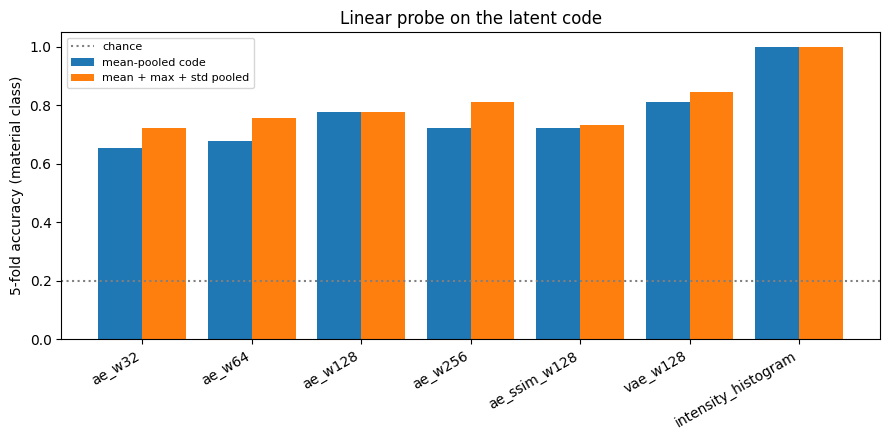

In [ ]:
import os, sys, json, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train
for mod in (ct_noise, ct_data, ct_models, ct_train):
    importlib.reload(mod)
from ct_data import extract_tiles

device = torch.device('cuda')

val_tiles = np.load(f'{PROJECT}/tiles/val_tiles_noisy.npy')
val_src = np.load(f'{PROJECT}/tiles/val_tile_source.npy')
val_lab = np.load(f'{PROJECT}/tiles/val_tile_label.npy')
val_ph_tiles = val_tiles[val_src == 1]
val_ph_labels = val_lab[val_src == 1][::4]

test_noisy = np.load(f'{PROJECT}/testsets/noisy_mixed.npy')
test_labels_all = np.load(f'{PROJECT}/testsets/labels.npy')
test_ph = test_noisy[test_labels_all >= 0]
test_ph_labels = test_labels_all[test_labels_all >= 0]
test_ph_tiles = np.concatenate([extract_tiles(s, 128, 128) for s in test_ph])

tiles = np.concatenate([val_ph_tiles, test_ph_tiles]).astype(np.float32)
y = np.concatenate([val_ph_labels, test_ph_labels])
n_ph = len(y)


@torch.no_grad()
def describe(model):
    means, stats = [], []
    for i in range(0, len(tiles), 120):
        x = torch.from_numpy(tiles[i:i + 120]).unsqueeze(1).to(device)
        mu, _ = model.encode(x)
        mu = mu.float()
        m = mu.mean(dim=(2, 3))
        flat = mu.flatten(2)
        means.append(m.cpu())
        stats.append(torch.cat([m, flat.max(dim=2).values, flat.std(dim=2)], dim=1).cpu())
    f_mean = torch.cat(means).numpy().reshape(n_ph, 4, -1).mean(axis=1)
    f_stats = torch.cat(stats).numpy().reshape(n_ph, 4, -1).mean(axis=1)
    return f_mean, f_stats


hist = np.stack([np.histogram(t, bins=32, range=(0.05, 1.05))[0] for t in tiles]).astype(np.float64)
hist = hist.reshape(n_ph, 4, -1).mean(axis=1)
hist = hist / hist.sum(axis=1, keepdims=True)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)


def probe(x):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=1.0))
    s = cross_val_score(clf, x, y, cv=cv)
    return float(s.mean()), float(s.std())


models = {
    'ae_w32': 'ae_final_w32',
    'ae_w64': 'ae_final_w64',
    'ae_w128': 'ae_final_w128',
    'ae_w256': 'ae_final_w256',
    'ae_ssim_w128': 'ae_ssim_w128',
    'vae_w128': 'vae_w128',
}
rows = []
for label, ckpt in models.items():
    model = ct_train.load_model(PROJECT, ckpt, device)
    f_mean, f_stats = describe(model)
    a1, s1 = probe(f_mean)
    a2, s2 = probe(f_stats)
    rows.append({'model': label, 'acc_mean_pool': a1, 'std_1': s1, 'acc_mean_max_std_pool': a2, 'std_2': s2})
h_acc, h_std = probe(hist)
rows.append({'model': 'intensity_histogram', 'acc_mean_pool': h_acc, 'std_1': h_std,
             'acc_mean_max_std_pool': h_acc, 'std_2': h_std})
table = pd.DataFrame(rows)
table.to_csv(f'{PROJECT}/results/latent_probe.csv', index=False)
print('chance level: 0.20 (5 classes), phantoms:', n_ph)
print(table.round(3).to_string(index=False))

x = np.arange(len(table))
plt.figure(figsize=(9, 4.5))
plt.bar(x - 0.2, table['acc_mean_pool'], 0.4, label='mean-pooled code')
plt.bar(x + 0.2, table['acc_mean_max_std_pool'], 0.4, label='mean + max + std pooled')
plt.axhline(0.2, color='gray', linestyle=':', label='chance')
plt.xticks(x, table['model'], rotation=30, ha='right')
plt.ylabel('5-fold accuracy (material class)')
plt.title('Linear probe on the latent code')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/latent_probe.png', dpi=150)
plt.show()

ae_w32 timed
ae_w64 timed
ae_w128 timed
ae_w256 timed
ae_ssim_w128 timed
vae_w128 timed
dncnn timed
       model  params_M  GFLOPs_per_tile  gpu_ms_per_slice  gpu_tiles_per_s  cpu_ms_per_slice  train_minutes  train_epochs  PSNR_dB  SSIM
      ae_w32     1.242            0.479             3.465         2331.261            78.086         11.474           200   34.858 0.936
      ae_w64     1.389            0.498             2.131         2358.047            48.688         11.474           200   34.855 0.935
     ae_w128     1.684            0.536             2.295         2390.611            48.607         11.606           200   35.072 0.938
     ae_w256     2.274            0.612             2.769         2351.827            52.160         11.887           200   34.996 0.938
ae_ssim_w128     1.684            0.536             2.313         2388.378            47.037         14.620           200   35.654 0.950
    vae_w128     1.979            0.574             2.425         2349.893    

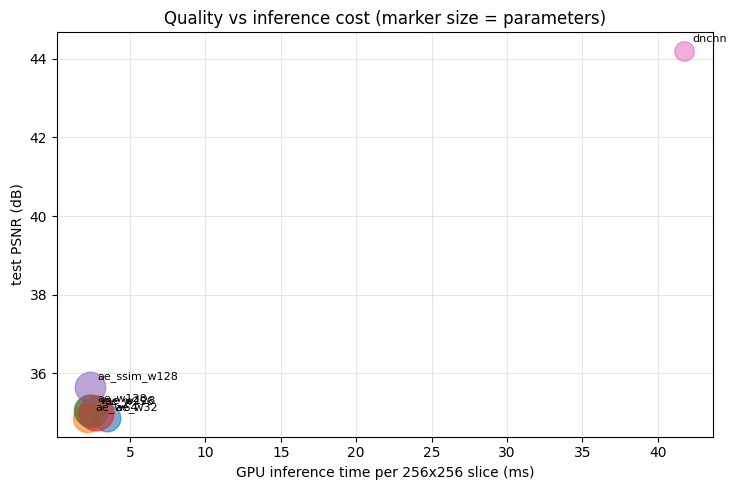


real test slices: how often does each method make the image worse than the noisy input?
ae_w128       worse than noisy:  70.8% | mean gain -2.18 dB | Spearman(detail, gain) = -0.21 (p = 0.02)
ae_ssim_w128  worse than noisy:  65.8% | mean gain -1.57 dB | Spearman(detail, gain) = -0.21 (p = 0.022)
dncnn         worse than noisy:   0.0% | mean gain +6.40 dB | Spearman(detail, gain) = +0.16 (p = 0.081)
nlm           worse than noisy:   0.0% | mean gain +4.90 dB | Spearman(detail, gain) = +0.10 (p = 0.26)


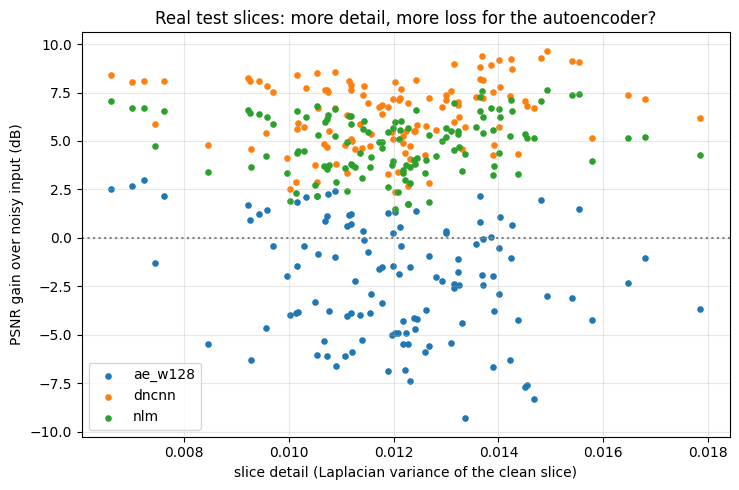

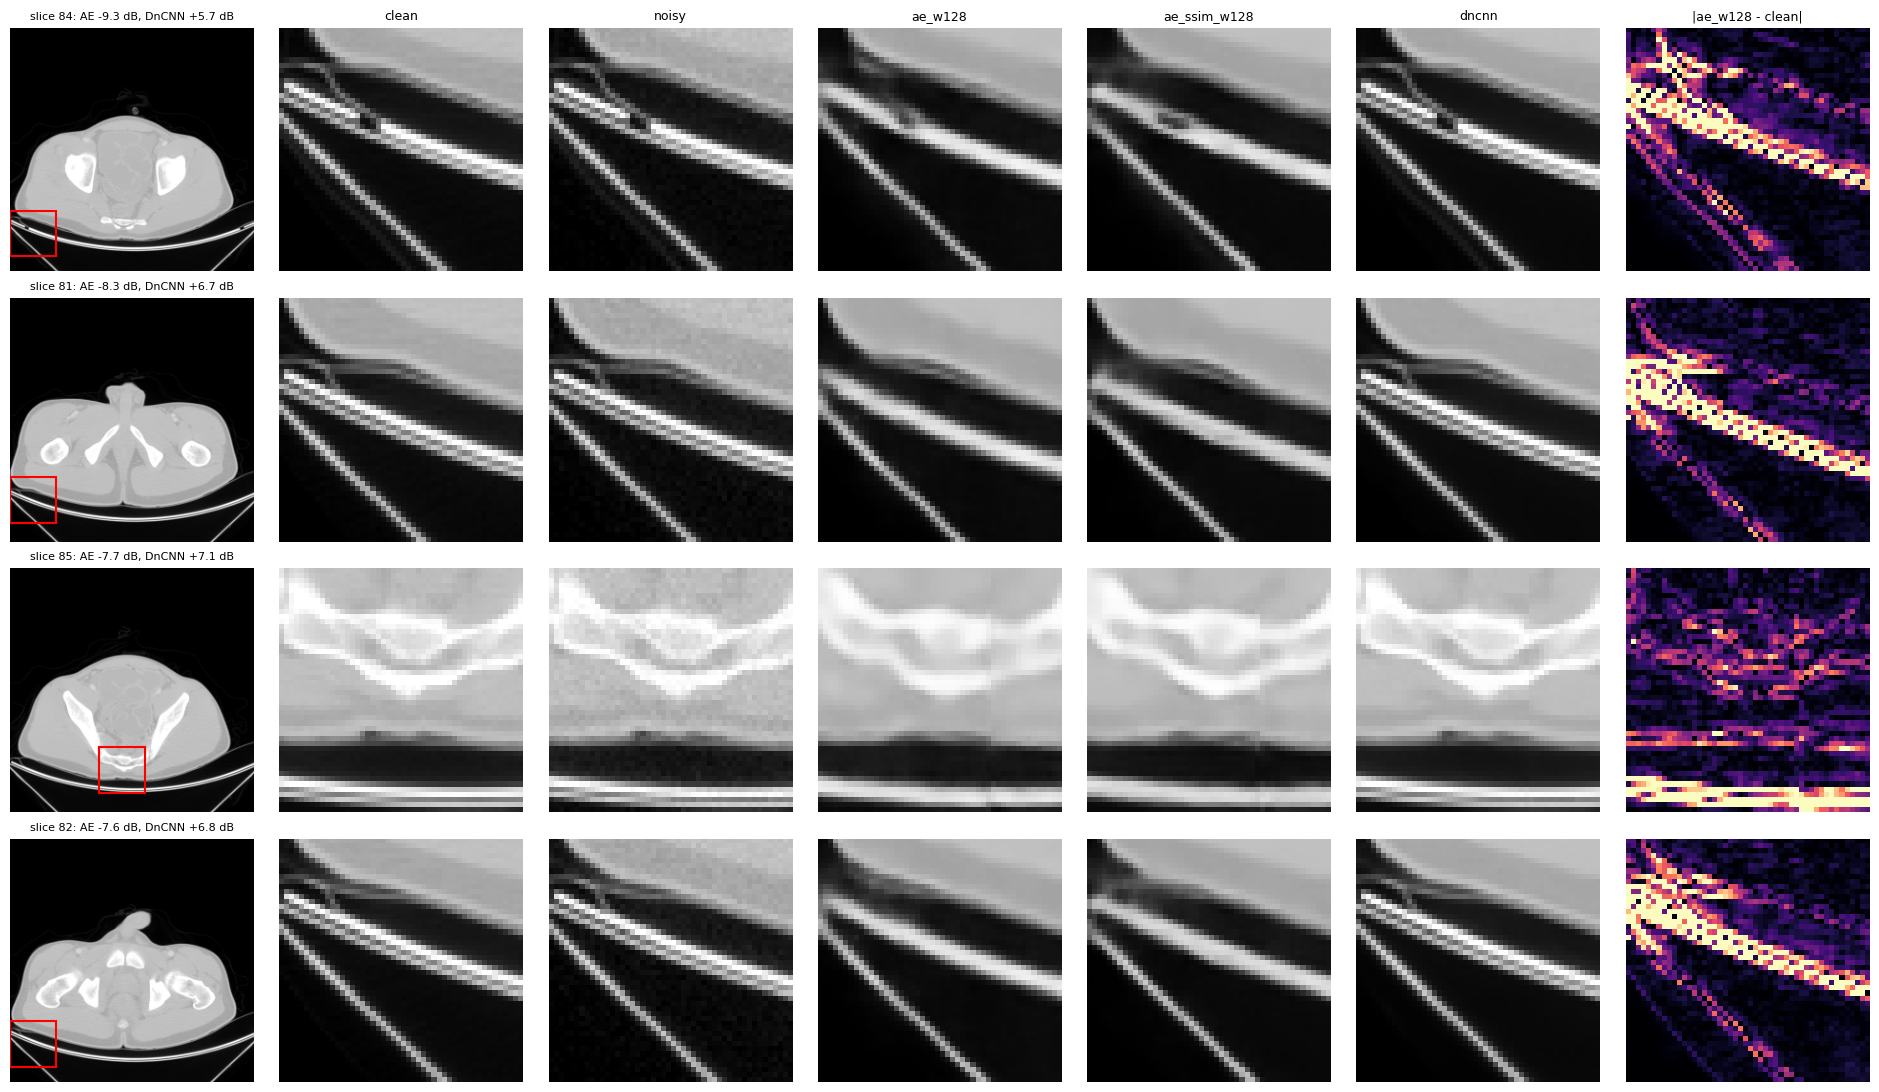

In [ ]:
import os, sys, json, time, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.stats import spearmanr
from scipy.ndimage import uniform_filter
from torch.utils.flop_counter import FlopCounterMode
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train, ct_metrics
for mod in (ct_noise, ct_data, ct_models, ct_train, ct_metrics):
    importlib.reload(mod)
from ct_metrics import psnr_each, lapvar_each

device = torch.device('cuda')
cpu = torch.device('cpu')
REPEATS = 30
BATCH = 64

models = {
    'ae_w32': 'ae_final_w32',
    'ae_w64': 'ae_final_w64',
    'ae_w128': 'ae_final_w128',
    'ae_w256': 'ae_final_w256',
    'ae_ssim_w128': 'ae_ssim_w128',
    'vae_w128': 'vae_w128',
    'dncnn': 'dncnn',
}


def sync(dev):
    if dev.type == 'cuda':
        torch.cuda.synchronize()


@torch.no_grad()
def time_model(model, dev, batch, repeats):
    x = torch.rand(batch, 1, 128, 128, device=dev)
    for _ in range(3):
        model(x)
    sync(dev)
    t0 = time.time()
    for _ in range(repeats):
        model(x)
    sync(dev)
    return (time.time() - t0) / repeats


rows = []
for label, ckpt in models.items():
    gpu_model = ct_train.load_model(PROJECT, ckpt, device)
    cpu_model = ct_train.load_model(PROJECT, ckpt, cpu)
    t_batch = time_model(gpu_model, device, BATCH, REPEATS)
    t_slice_gpu = time_model(gpu_model, device, 4, REPEATS)
    t_slice_cpu = time_model(cpu_model, cpu, 4, max(3, REPEATS // 10))
    try:
        with FlopCounterMode(display=False) as fc:
            with torch.no_grad():
                cpu_model(torch.rand(1, 1, 128, 128))
        gflops = fc.get_total_flops() / 1e9
    except Exception:
        gflops = float('nan')
    h = pd.read_csv(f'{PROJECT}/results/history_{ckpt}.csv')
    rows.append({
        'model': label,
        'params_M': ct_models.count_params(gpu_model) / 1e6,
        'GFLOPs_per_tile': gflops,
        'gpu_ms_per_slice': t_slice_gpu * 1000,
        'gpu_tiles_per_s': BATCH / t_batch,
        'cpu_ms_per_slice': t_slice_cpu * 1000,
        'train_minutes': h['seconds'].sum() / 60,
        'train_epochs': len(h),
    })
    print(label, 'timed')

quality = pd.read_csv(f'{PROJECT}/results/main_results_mixed.csv', index_col=0)
bench = pd.DataFrame(rows)
bench['PSNR_dB'] = bench['model'].map(quality['PSNR_all'])
bench['SSIM'] = bench['model'].map(quality['SSIM_all'])
bench.to_csv(f'{PROJECT}/results/benchmark.csv', index=False)
print(bench.round(3).to_string(index=False))

plt.figure(figsize=(7.5, 5))
for _, r in bench.iterrows():
    plt.scatter(r['gpu_ms_per_slice'], r['PSNR_dB'], s=60 + 250 * r['params_M'], alpha=0.6)
    plt.annotate(r['model'], (r['gpu_ms_per_slice'], r['PSNR_dB']), fontsize=8,
                 xytext=(6, 6), textcoords='offset points')
plt.xlabel('GPU inference time per 256x256 slice (ms)')
plt.ylabel('test PSNR (dB)')
plt.title('Quality vs inference cost (marker size = parameters)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/quality_vs_cost.png', dpi=150)
plt.show()

clean = np.load(f'{PROJECT}/testsets/clean.npy')
labels = np.load(f'{PROJECT}/testsets/labels.npy')
noisy = np.clip(np.load(f'{PROJECT}/testsets/noisy_mixed.npy'), 0, 1)
preds = {k: np.load(f'{PROJECT}/results/preds/{k}_mixed.npy')
         for k in ['ae_w128', 'ae_ssim_w128', 'dncnn', 'nlm']}
real = np.where(labels < 0)[0]
p_noisy = psnr_each(clean, noisy)
gain = {k: psnr_each(clean, v) - p_noisy for k, v in preds.items()}
detail = lapvar_each(clean)

print('\nreal test slices: how often does each method make the image worse than the noisy input?')
for k in preds:
    g = gain[k][real]
    rho, pval = spearmanr(detail[real], g)
    print(f'{k:13s} worse than noisy: {(g < 0).mean() * 100:5.1f}% | mean gain {g.mean():+.2f} dB | '
          f'Spearman(detail, gain) = {rho:+.2f} (p = {pval:.2g})')

plt.figure(figsize=(7.5, 5))
for k in ['ae_w128', 'dncnn', 'nlm']:
    plt.scatter(detail[real], gain[k][real], s=14, label=k)
plt.axhline(0, color='gray', linestyle=':')
plt.xlabel('slice detail (Laplacian variance of the clean slice)')
plt.ylabel('PSNR gain over noisy input (dB)')
plt.title('Real test slices: more detail, more loss for the autoencoder?')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/detail_vs_gain.png', dpi=150)
plt.show()

worst = real[np.argsort(gain['ae_w128'][real])[:4]]
fig, axes = plt.subplots(4, 7, figsize=(19, 11))
for r, i in enumerate(worst):
    err = (preds['ae_w128'][i] - clean[i]) ** 2
    local = uniform_filter(err, size=48, mode='constant')
    cy, cx = np.unravel_index(np.argmax(local), local.shape)
    y0 = int(np.clip(cy - 24, 0, 256 - 48))
    x0 = int(np.clip(cx - 24, 0, 256 - 48))
    sl = (slice(y0, y0 + 48), slice(x0, x0 + 48))
    axes[r, 0].imshow(clean[i], cmap='gray', vmin=0, vmax=1)
    axes[r, 0].add_patch(Rectangle((x0 - 0.5, y0 - 0.5), 48, 48, fill=False, edgecolor='red', lw=1.5))
    axes[r, 0].set_title(f'slice {i}: AE {gain["ae_w128"][i]:+.1f} dB, DnCNN {gain["dncnn"][i]:+.1f} dB', fontsize=8)
    panels = [('clean', clean[i]), ('noisy', noisy[i]), ('ae_w128', preds['ae_w128'][i]),
              ('ae_ssim_w128', preds['ae_ssim_w128'][i]), ('dncnn', preds['dncnn'][i])]
    for c, (name, img) in enumerate(panels, start=1):
        axes[r, c].imshow(img[sl], cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        if r == 0:
            axes[r, c].set_title(name, fontsize=9)
    axes[r, 6].imshow(np.abs(preds['ae_w128'][i] - clean[i])[sl], cmap='magma', vmin=0, vmax=0.15, interpolation='nearest')
    if r == 0:
        axes[r, 6].set_title('|ae_w128 - clean|', fontsize=9)
    for c in range(7):
        axes[r, c].axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/failure_cases.png', dpi=150)
plt.show()

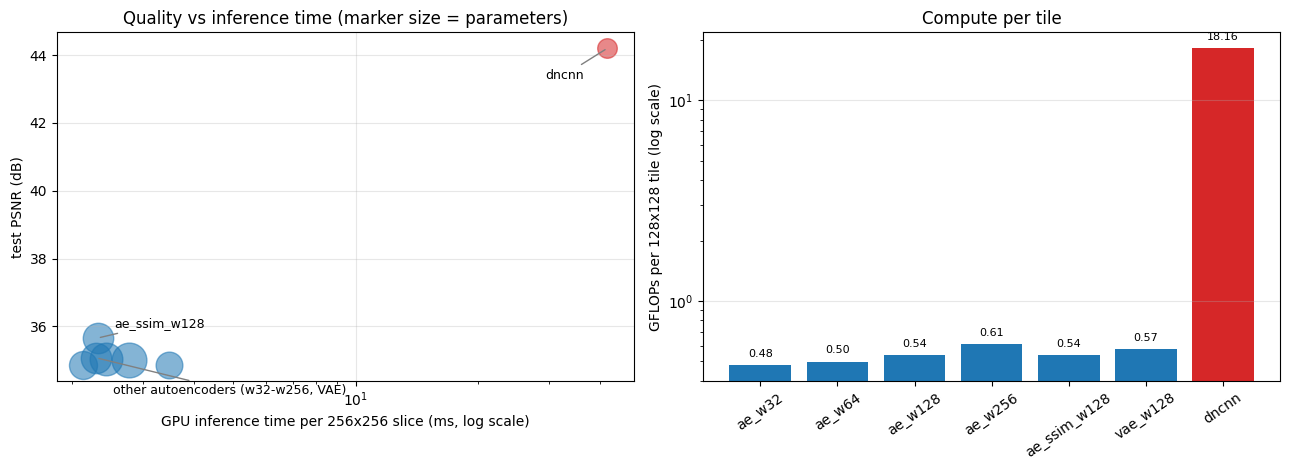

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
bench = pd.read_csv(f'{PROJECT}/results/benchmark.csv')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for _, r in bench.iterrows():
    colour = 'tab:red' if r['model'] == 'dncnn' else 'tab:blue'
    ax[0].scatter(r['gpu_ms_per_slice'], r['PSNR_dB'], s=60 + 250 * r['params_M'], alpha=0.55, color=colour)
for name, text, offset in [('dncnn', 'dncnn', (-45, -22)),
                           ('ae_ssim_w128', 'ae_ssim_w128', (12, 8)),
                           ('ae_w128', 'other autoencoders (w32-w256, VAE)', (12, -26))]:
    r = bench[bench.model == name].iloc[0]
    ax[0].annotate(text, (r['gpu_ms_per_slice'], r['PSNR_dB']), xytext=offset,
                   textcoords='offset points', fontsize=9, arrowprops=dict(arrowstyle='-', color='gray'))
ax[0].set_xscale('log')
ax[0].set_xlabel('GPU inference time per 256x256 slice (ms, log scale)')
ax[0].set_ylabel('test PSNR (dB)')
ax[0].set_title('Quality vs inference time (marker size = parameters)')
ax[0].grid(alpha=0.3)

colours = ['tab:red' if m == 'dncnn' else 'tab:blue' for m in bench['model']]
ax[1].bar(bench['model'], bench['GFLOPs_per_tile'], color=colours)
ax[1].set_yscale('log')
ax[1].set_ylabel('GFLOPs per 128x128 tile (log scale)')
ax[1].set_title('Compute per tile')
ax[1].tick_params(axis='x', rotation=35)
for i, v in enumerate(bench['GFLOPs_per_tile']):
    ax[1].text(i, v * 1.1, f'{v:.2f}', ha='center', fontsize=8)
ax[1].grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/quality_vs_cost.png', dpi=150)
plt.show()

In [ ]:
import os, sys, glob, json, zipfile
import importlib.metadata as md
import pandas as pd
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
OUT = f'{PROJECT}/submission'
os.makedirs(OUT, exist_ok=True)


def version(names):
    for n in names:
        try:
            return f'{n}=={md.version(n)}'
        except md.PackageNotFoundError:
            continue
    return None


reqs = [version(n) for n in (['numpy'], ['scipy'], ['pandas'], ['matplotlib'], ['scikit-image'],
                             ['scikit-learn'], ['opencv-python', 'opencv-python-headless'],
                             ['nibabel'], ['torch'])]
with open(f'{PROJECT}/requirements.txt', 'w') as f:
    f.write('\n'.join(r for r in reqs if r) + '\n')

main = pd.read_csv(f'{PROJECT}/results/main_results_mixed.csv', index_col=0)
table = ['| Method | PSNR (dB) | SSIM | Laplacian variance |', '|---|---|---|---|']
for name, r in main.iterrows():
    table.append(f'| {name} | {r["PSNR_all"]:.2f} | {r["SSIM_all"]:.3f} | {r["LapVar_all"]:.4f} |')

readme = f"""# Autoencoder-based CT denoising

Convolutional denoising autoencoders (plain, variational, and with a composite MSE+SSIM loss) for 2D CT slices,
compared with a DnCNN-style residual CNN and with Gaussian, median and non-local-means filters.

## Data
- 41 CT volumes from the Medical Segmentation Decathlon, Task 09 (spleen). 20 body slices per volume, 820 real slices,
  clipped to [-1000, 400] HU, per-volume min-max normalised, resampled to 256x256, split by volume (29 / 6 / 6).
- 300 synthetic multi-material phantoms (5 material classes, split 210 / 45 / 45).
- Noise: Poisson photon noise (N0 between 5e4 and 2e5, log-uniform) followed by Gaussian read noise (sigma 1-3% of the range).
- 128x128 tiles (4 per 256x256 slice) for training; full slices are reassembled for testing.

## Layout
- `ct_noise.py` noise model (NumPy and PyTorch versions)
- `ct_data.py` tiling, reassembly and augmentation
- `ct_models.py` autoencoder, variational autoencoder, DnCNN
- `ct_train.py` training loop, loss functions, model loading, tiled inference
- `ct_metrics.py` PSNR, SSIM, MSE, Laplacian variance and the classical filters
- `results/` metric tables (CSV) and training histories
- `figures/` all figures used in the report
- `models/` trained weights (.pt)
- the notebook runs the pipeline in the order: data download, slice and phantom generation, noise model, tiling,
  classical baselines, training, evaluation, latent-space analysis, benchmark and failure cases

## Training recipe
{json.dumps(json.load(open(f'{PROJECT}/results/final_recipe.json')))}

## Test results (mixed-dose test set, full slices)
{chr(10).join(table)}

## Reproducing
Install the packages in `requirements.txt`, mount the project folder, and run the notebook top to bottom on a GPU runtime.
Seeds are fixed (42 for splits and training, fixed seeds for the test noise).

## Data source
Antonelli et al., The Medical Segmentation Decathlon, Nature Communications 13, 4128 (2022).
"""
with open(f'{PROJECT}/README.md', 'w') as f:
    f.write(readme)


def add(z, pattern, base=PROJECT):
    for p in sorted(glob.glob(pattern)):
        if os.path.isfile(p):
            z.write(p, os.path.relpath(p, base))


with zipfile.ZipFile(f'{OUT}/report_data.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for pat in ['results/*.csv', 'results/*.json', 'figures/*.png', '*.json', 'testsets/conditions.json',
                'phantoms/phantom_meta.json', 'README.md', 'requirements.txt']:
        add(z, f'{PROJECT}/{pat}')

final_models = ['ae_final_w32', 'ae_final_w64', 'ae_final_w128', 'ae_final_w256', 'ae_ssim_w128', 'vae_w128', 'dncnn']
with zipfile.ZipFile(f'{OUT}/submission_package.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for pat in ['*.py', 'README.md', 'requirements.txt', 'results/*.csv', 'results/*.json', 'figures/*.png', '*.json']:
        add(z, f'{PROJECT}/{pat}')
    for m in final_models:
        add(z, f'{PROJECT}/models/{m}.pt')

for name in ['report_data.zip', 'submission_package.zip']:
    size = os.path.getsize(f'{OUT}/{name}') / 1e6
    with zipfile.ZipFile(f'{OUT}/{name}') as z:
        print(f'{name}: {size:.1f} MB, {len(z.namelist())} files')
print('saved in:', OUT)

report_data.zip: 7.8 MB, 55 files
submission_package.zip: 48.2 MB, 65 files
saved in: /content/drive/MyDrive/ct_dae_project/submission


Mounted at /content/drive
recipe in use: {'kind': 'ae', 'batch_size': 8, 'lr': 0.001, 'epochs': 200, 'schedule': 'cosine'}
ae_final_w16 ep   1 train 0.009397 val 0.004107 psnr 25.19 lr 1.0e-03 6.5s *
ae_final_w16 ep   2 train 0.003808 val 0.002849 psnr 26.75 lr 1.0e-03 3.3s *
ae_final_w16 ep   3 train 0.002709 val 0.002285 psnr 27.65 lr 1.0e-03 3.6s *
ae_final_w16 ep   4 train 0.002269 val 0.002117 psnr 27.86 lr 1.0e-03 3.4s *
ae_final_w16 ep   5 train 0.001962 val 0.001798 psnr 28.40 lr 1.0e-03 3.3s *
ae_final_w16 ep   6 train 0.001783 val 0.002491 psnr 26.77 lr 1.0e-03 3.4s
ae_final_w16 ep   7 train 0.001685 val 0.001447 psnr 29.68 lr 1.0e-03 3.4s *
ae_final_w16 ep   8 train 0.001593 val 0.001406 psnr 29.78 lr 1.0e-03 3.3s *
ae_final_w16 ep   9 train 0.001473 val 0.001361 psnr 29.83 lr 1.0e-03 3.5s *
ae_final_w16 ep  10 train 0.001424 val 0.001200 psnr 30.46 lr 9.9e-04 3.4s *
ae_final_w16 ep  11 train 0.001338 val 0.001202 psnr 30.47 lr 9.9e-04 3.3s
ae_final_w16 ep  12 train 0.001289

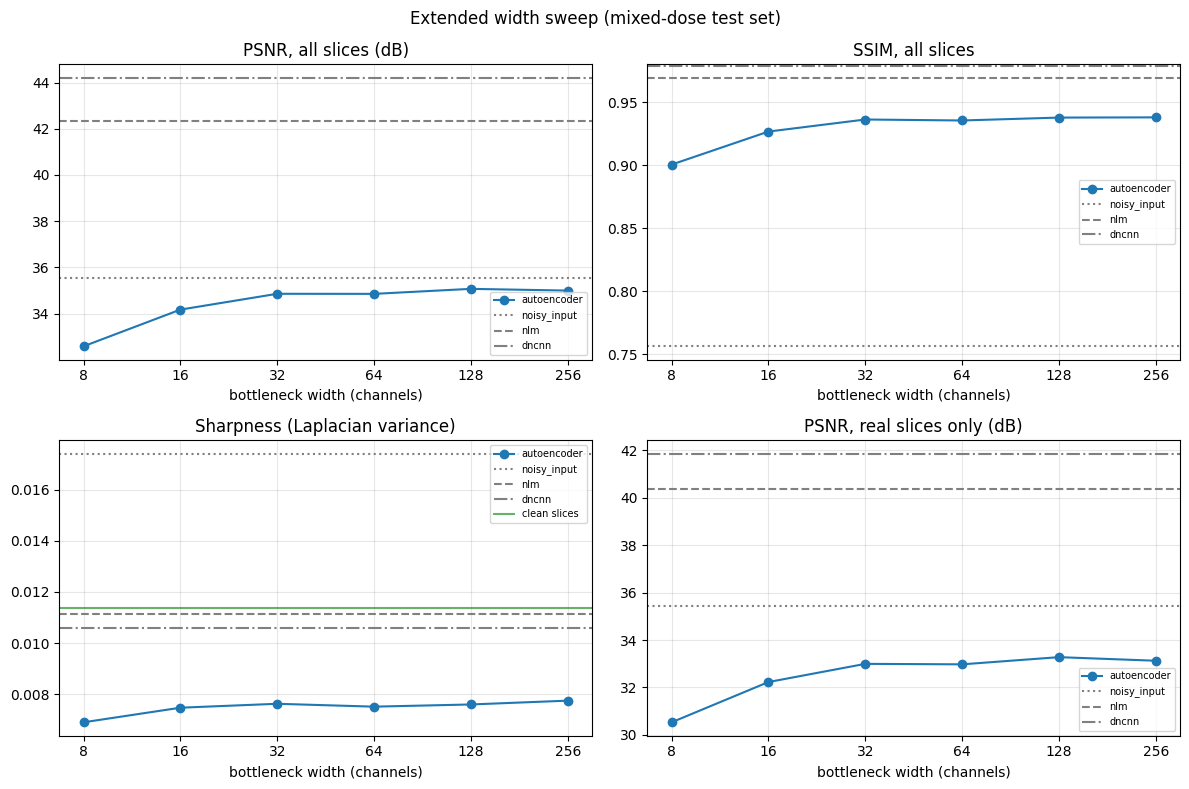

In [ ]:
import os, sys, json, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')

PROJECT = '/content/drive/MyDrive/ct_dae_project'
sys.path.insert(0, PROJECT)
import ct_noise, ct_data, ct_models, ct_train, ct_metrics
for mod in (ct_noise, ct_data, ct_models, ct_train, ct_metrics):
    importlib.reload(mod)
from ct_metrics import evaluate, lapvar_each

with open(f'{PROJECT}/results/final_recipe.json') as f:
    recipe = json.load(f)
print('recipe in use:', recipe)

device = torch.device('cuda')
data = ct_train.load_tensors(PROJECT, device)

for width in [16, 8]:
    ct_train.train_model(PROJECT, f'ae_final_w{width}', 'ae', width, data, loss_type='mse',
                         epochs=recipe['epochs'], batch_size=recipe['batch_size'], lr=recipe['lr'],
                         patience=60, schedule='cosine')

clean = np.load(f'{PROJECT}/testsets/clean.npy')
labels = np.load(f'{PROJECT}/testsets/labels.npy')
with open(f'{PROJECT}/testsets/conditions.json') as f:
    conditions = json.load(f)
SEL = np.arange(len(clean))
clean, labels = clean[SEL], labels[SEL]

rows = []
for width in [8, 16]:
    model = ct_train.load_model(PROJECT, f'ae_final_w{width}', device)
    for cond in conditions:
        noisy = np.load(f'{PROJECT}/testsets/noisy_{cond}.npy')[SEL]
        for stride in ([128, 64] if cond == 'mixed' else [128]):
            pred = np.clip(ct_train.predict_slices(model, noisy, device, stride=stride), 0.0, 1.0)
            m, _ = evaluate(clean, pred, labels)
            rows.append({'condition': cond, 'method': f'ae_w{width}', 'stride': str(stride), **m})
            if cond == 'mixed' and stride == 128:
                np.save(f'{PROJECT}/results/preds/ae_w{width}_mixed.npy', pred.astype(np.float32))
    print(f'ae_w{width} evaluated')
new_df = pd.DataFrame(rows)
new_df.to_csv(f'{PROJECT}/results/deep_metrics_extra_widths.csv', index=False)

all_df = pd.read_csv(f'{PROJECT}/results/all_metrics.csv')
all_df['stride'] = all_df['stride'].apply(lambda v: 'n/a' if pd.isna(v) else str(int(float(v))))
full = pd.concat([all_df, new_df], ignore_index=True)
widths = [8, 16, 32, 64, 128, 256]
cols = ['PSNR_all', 'SSIM_all', 'LapVar_all', 'PSNR_real', 'SSIM_real', 'PSNR_phantom', 'SSIM_phantom']
names = [f'ae_w{w}' for w in widths]
params = [ct_models.count_params(ct_models.build_model('ae', w)) / 1e6 for w in widths]

tables = {}
for stride in ['128', '64']:
    t = full[(full.condition == 'mixed') & (full.stride == stride)].set_index('method').loc[names, cols].copy()
    t.insert(0, 'params_M', params)
    tables[stride] = t
tables['128'].to_csv(f'{PROJECT}/results/width_sweep_extended.csv')
tables['64'].to_csv(f'{PROJECT}/results/width_sweep_extended_blended.csv')
print('\nwidth sweep, mixed-dose test set, no overlap (stride 128)')
print(tables['128'].round(4).to_string())
print('\nwidth sweep, mixed-dose test set, blended overlap (stride 64)')
print(tables['64'][['params_M', 'PSNR_all', 'SSIM_all', 'LapVar_all']].round(4).to_string())

ref = pd.read_csv(f'{PROJECT}/results/main_results_mixed.csv', index_col=0)
clean_sharp = float(lapvar_each(clean).mean())
panels = [('PSNR_all', 'PSNR, all slices (dB)'), ('SSIM_all', 'SSIM, all slices'),
          ('LapVar_all', 'Sharpness (Laplacian variance)'), ('PSNR_real', 'PSNR, real slices only (dB)')]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes.ravel(), panels):
    ax.plot(widths, tables['128'][col].values, 'o-', label='autoencoder')
    for name, style in [('noisy_input', ':'), ('nlm', '--'), ('dncnn', '-.')]:
        ax.axhline(ref.loc[name, col], linestyle=style, color='gray', label=name)
    if col == 'LapVar_all':
        ax.axhline(clean_sharp, linestyle='-', color='green', alpha=0.6, label='clean slices')
    ax.set_xscale('log', base=2)
    ax.set_xticks(widths)
    ax.set_xticklabels(widths)
    ax.set_xlabel('bottleneck width (channels)')
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
plt.suptitle('Extended width sweep (mixed-dose test set)')
plt.tight_layout()
plt.savefig(f'{PROJECT}/figures/width_sweep_extended.png', dpi=150)
plt.show()